# Imports

## Import the folder for compatibility (if running local)

In [1]:
import os
import sys

project_root = "Incremental-Learning-MycroftMinds"
cwd = os.path.abspath(os.getcwd())
while True:
    if os.path.basename(cwd) == project_root:
        if cwd not in sys.path:
            sys.path.insert(0, cwd)
        break
    parent = os.path.dirname(cwd)
    if parent == cwd:
        raise FileNotFoundError(f"Project root '{project_root}' not found in any parent directory.")
    cwd = parent

## Import external libs and internal models

In [2]:
import time
import pandas as pd

from src.data.io import load_dataset
from src.utils.memory import calculate_memory_usage
from src.evaluation.metrics import all_time_aggregation_metrics
from src.evaluation.visualization import plot_hourly_predictions
from src.evaluation.training import all_valid_splits_seq_fit_predict, test_set_seq_fit_predict

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from river.forest import ARFRegressor
from river.tree import HoeffdingTreeRegressor
from src.evaluation.baseline import PreviousValueRegressor, SeasonalMeanRegressor
from src.trees import fastodt
from src.bagging import ARFRegressorFODT
from src.boosting import IncubationBoost
from src.ensemble_methods.IncubationBoostElastic import IncubationBoostElastic
from src.ensemble_methods import elasticGBDT

import ipywidgets as widgets
widgets.IntSlider()

IntSlider(value=0)

# Download the splitted data

In [3]:
# check you data dir and file prefixes
data_dir = '../../data/other_data/'

## Pick the hourly granularity data
- WFV, train+=28 (train set increasing), validation=28, hourly granularity

## Evaluation Settings

In [4]:
DATA_FREQUENCY = 'H'  # 1-Hour frequency
FORECAST_HORIZON = '1h'  # 1-Hour forecast horizon
SPIKE_PROMINENCE = 5  # Prominence for spike detection, adjusted after EDA
USE_RESIDUAL = True

In [5]:
# Measure loading time
start_time = time.time()

# Load data

train, valid, test = load_dataset(data_dir=data_dir, prefix='od_electricity_hour_wfv', use_numpy=True)

ALL_FEATURES = ['time', 'device_id', 'hour', 'weekday', 'month', 
                'Global_active_power_lag_1h', 'Global_active_power_lag_2h', 'Global_active_power_lag_24h', 'Global_active_power_lag_168h', 
                'Voltage_lag_1h', 'Voltage_lag_2h', 'Voltage_lag_24h', 'Voltage_lag_168h', 
                'Global_reactive_power_lag_1h', 'Global_reactive_power_lag_2h', 'Global_reactive_power_lag_24h', 'Global_reactive_power_lag_168h']


loading_time = time.time() - start_time
print(f"Data loaded in {loading_time/60:.2f} minutes")

[INFO] Loading train data...
[INFO] Train data loaded: 40 samples
[INFO] Loading valid data...
[INFO] Valid data loaded: 40 samples
[INFO] Loading test data...
[INFO] Test data loaded: 2 samples
Data loaded in 0.09 minutes


## Data structure information

The data structure is as follows:
- For walk-forward validation:
  - `train` is a list of tuples, where each tuple is (X, y) for one split
  - `valid` is a list of tuples, where each tuple is (X, y) for one split
  - `test` is a tuple of (X, y)
- Each X array contains:
  - Column 0: `time` (`pandas.Timedelta`)
  - Column 1: `device_id` (`str`)
  - Other columns: time-related features and lag features

The memory usage of the loaded data is printed below:

In [6]:
# Print data structure and memory usage information
if isinstance(train, list):
    print(f"Training data: {len(train)} splits")
    print(f"Validation data: {len(valid)} splits")
    
    # Show first split shape
    print(f"First train split shape: X={train[0][0].shape}, y={train[0][1].shape}")
    print(f"First valid split shape: X={valid[0][0].shape}, y={valid[0][1].shape}")
    
    # Memory usage
    train_mem = sum(calculate_memory_usage(ts) for ts in train)
    valid_mem = sum(calculate_memory_usage(vs) for vs in valid)
    test_mem = calculate_memory_usage(test)
    
    print(f"\nMemory usage:")
    print(f"Train: {train_mem:.2f} MB")
    print(f"Valid: {valid_mem:.2f} MB")
    print(f"Test: {test_mem:.2f} MB")
    print(f"Total: {train_mem + valid_mem + test_mem:.2f} MB")
else:
    # For non-list structure
    print(f"Training data shape: X={train[0].shape}, y={train[1].shape}")
    print(f"Validation data shape: X={valid[0].shape}, y={valid[1].shape}")
    print(f"Test data shape: X={test[0].shape}, y={test[1].shape}")

Training data: 40 splits
Validation data: 40 splits
First train split shape: X=(672, 17), y=(672,)
First valid split shape: X=(672, 17), y=(672,)

Memory usage:
Train: 75.69 MB
Valid: 3.70 MB
Test: 0.95 MB
Total: 80.33 MB


# WFV Model Evaluation
(train+valid WFV)
- (1) `train[0]` vs `valid[0]`
- (2) `train[1]` vs `valid[1]`
- ...
- (n) `train[n]` vs `valid[n]`

, where: 
$$ train[1] = train[0]+valid[0] $$
$$...$$
$$ train[n] = train[0]+valid[0]+valid[1]+...+valid[n-1] $$

### Baseline model (seasonal averages)

In [7]:
update_freq = "14D"
bl_mean = SeasonalMeanRegressor
bl_mean_params = {}

In [8]:
bl_mean_train_period_predictions, bl_mean_valid_period_predictions,\
bl_mean_train_period_metrics, bl_mean_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=bl_mean,
    model_params=bl_mean_params,
    train=train,
    valid=valid,
    incremental=False,
    use_residuals=USE_RESIDUAL,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    verbose=True
)

Processing splits:   0%|          | 0/40 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2006-12-23 19:00:00+01:00 to 2007-01-20 17:00:00+01:00

Time: 0.01 seconds
Predicting for chunk from 2007-01-20 18:00:00+01:00 to 2007-02-03 18:00:00+01:00

-------------------------

Retraining model on data from 2006-12-23 19:00:00+01:00 to 2007-02-03 18:00:00+01:00

Time: 0.00 seconds
Predicting for chunk from 2007-02-03 19:00:00+01:00 to 2007-02-17 17:00:00+01:00

-------------------------
Model's memory usage: 0.024628 MB
Metrics for Device: const | Period: 2007-01-20 18:00:00+01:00 - 2007-02-17 17:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.7946
	MAE: 0.5640
	MAPE: 50.9160%

Directional Metrics:
	Directional Accuracy: 55.4396%
	First-Diff Correlation: 0.0816

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1429
		Recall: 0.3333
		F1: 0.2000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2006-12-23 19:00:00+01:00 to 2007-02-17 17:00:00+01:00

Time: 0.00 seconds
Predicting for chunk from 2007-02-17 18:00:00+01:00 to 2007-03-03 18:00:00+01:00

-------------------------

Retraining model on data from 2006-12-23 19:00:00+01:00 to 2007-03-03 18:00:00+01:00

Time: 0.00 seconds
Predicting for chunk from 2007-03-03 19:00:00+01:00 to 2007-03-17 17:00:00+01:00

-------------------------
Model's memory usage: 0.024490 MB
Metrics for Device: const | Period: 2007-02-17 18:00:00+01:00 - 2007-03-17 17:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.7213
	MAE: 0.5033
	MAPE: 71.7563%

Directional Metrics:
	Directional Accuracy: 51.4158%
	First-Diff Correlation: 0.0459

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (71 outputs left out)

Processing devices in split 38:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2006-12-23 19:00:00+01:00 to 2009-12-19 17:00:00+01:00

Time: 0.02 seconds
Predicting for chunk from 2009-12-19 18:00:00+01:00 to 2010-01-02 18:00:00+01:00

-------------------------

Retraining model on data from 2006-12-23 19:00:00+01:00 to 2010-01-02 18:00:00+01:00

Time: 0.02 seconds
Predicting for chunk from 2010-01-02 19:00:00+01:00 to 2010-01-16 17:00:00+01:00

-------------------------
Model's memory usage: 0.024170 MB
Metrics for Device: const | Period: 2009-12-19 18:00:00+01:00 - 2010-01-16 17:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.6490
	MAE: 0.4363
	MAPE: 41.2008%

Directional Metrics:
	Directional Accuracy: 57.2280%
	First-Diff Correlation: 0.0455

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1429
		Recall: 0.1667
		F1: 0.1538
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=

Processing devices in split 39:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2006-12-23 19:00:00+01:00 to 2010-01-16 17:00:00+01:00

Time: 0.02 seconds
Predicting for chunk from 2010-01-16 18:00:00+01:00 to 2010-01-30 18:00:00+01:00

-------------------------

Retraining model on data from 2006-12-23 19:00:00+01:00 to 2010-01-30 18:00:00+01:00

Time: 0.01 seconds
Predicting for chunk from 2010-01-30 19:00:00+01:00 to 2010-02-11 15:00:00+01:00

-------------------------
Model's memory usage: 0.024170 MB
Metrics for Device: const | Period: 2010-01-16 18:00:00+01:00 - 2010-02-11 15:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.6458
	MAE: 0.4458
	MAPE: 38.3056%

Directional Metrics:
	Directional Accuracy: 52.0129%
	First-Diff Correlation: 0.0514

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=

#### Results

In [9]:
print("\n\nValid period metrics:")
bl_mean_all_time_valid_metrics = all_time_aggregation_metrics(bl_mean_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Valid period metrics:


Aggregated Metrics Across Periods
Device ID: const
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.6357 ± 0.0906
	MAE: 0.4342 ± 0.0634
	MAPE: 55.5469% ± 15.3595%

	Directional Metrics:
		Directional Accuracy: 52.8018% ± 3.2629%
		First-Diff Correlation: 0.0053 ± 0.0831

	Immediate Detection (delta=0):
		Spike Precision: 0.0468 ± 0.0622
		Spike Recall: 0.0392 ± 0.0668
		Spike F1: 0.0402 ± 0.0576
		Drop Precision: 0.0463 ± 0.0646
		Drop Recall: 0.0399 ± 0.0677
		Drop F1: 0.0385 ± 0.0554

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.7614 ± 0.2343
		Spike Recall: 0.7002 ± 0.2349
		Spike F1: 0.6783 ± 0.1762
		Drop Precision: 0.2018 ± 0.1469
		Drop Recall: 0.1642 ± 0.1112
		Drop F1: 0.1690 ± 0.1136
Daily Metrics:
	RMSE: 1.0212 ± 0.2044
	MAE: 0.7828 ± 0.1697
	MAPE: 3.6011% ± 1.0523%

	Directional Metrics:
		Directional Accuracy: 93.4684% ± 5.2928%
		First-Diff Correlation: 0.9786 ± 0.0121

	Immediate Detection (delta=0):
		Spi

#### Validation plots

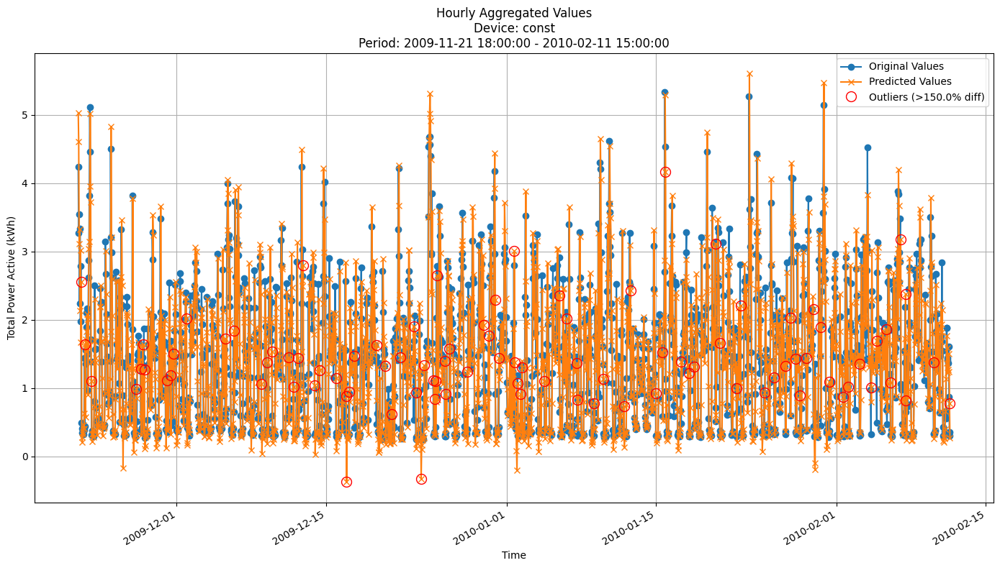


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.6403
MAE: 0.4381
MAPE: 39.7723%

Directional Metrics:
Directional Accuracy: 54.4020%
First-Diff Correlation: 0.0501

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [10]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in bl_mean_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, bl_mean_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, bl_mean_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5,
                            )

### Baseline model (predict previous value)

In [11]:
update_freq = "1H"
bl_prev = PreviousValueRegressor
bl_prev_params = {'is_residual': USE_RESIDUAL}

In [12]:
bl_prev_train_period_predictions, bl_prev_valid_period_predictions,\
bl_prev_train_period_metrics, bl_prev_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=bl_prev,
    model_params=bl_prev_params,
    train=train,
    valid=valid,
    use_residuals=USE_RESIDUAL,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    verbose=True
)

Processing splits:   0%|          | 0/40 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 15
Filtered feature count: 15
Excluded lag features: None
Initial training on data from 2006-12-23 19:00:00+01:00 to 2007-01-20 17:00:00+01:00
Model's memory usage: 0.000511 MB
Metrics for Device: const | Period: 2007-01-20 18:00:00+01:00 - 2007-02-17 17:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.8262
	MAE: 0.5665
	MAPE: 45.7958%

Directional Metrics:
	Directional Accuracy: 50.3726%
	First-Diff Correlation: -0.0129

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------


Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 15
Filtered feature count: 15
Excluded lag features: None
Initial training on data from 2006-12-23 19:00:00+01:00 to 2007-02-17 17:00:00+01:00
Model's memory usage: 0.000504 MB
Metrics for Device: const | Period: 2007-02-17 18:00:00+01:00 - 2007-03-17 17:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.7394
	MAE: 0.4517
	MAPE: 45.1054%

Directional Metrics:
	Directional Accuracy: 44.2623%
	First-Diff Correlation: -0.0331

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 0.9524
		F1: 0.9756
--------------------------------------------------


Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (71 outputs left out)

Processing devices in split 38:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 15
Filtered feature count: 15
Excluded lag features: None
Initial training on data from 2006-12-23 19:00:00+01:00 to 2009-12-19 17:00:00+01:00
Model's memory usage: 0.000313 MB
Metrics for Device: const | Period: 2009-12-19 18:00:00+01:00 - 2010-01-16 17:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.6979
	MAE: 0.4648
	MAPE: 41.6371%

Directional Metrics:
	Directional Accuracy: 52.0119%
	First-Diff Correlation: -0.0275

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------


Processing devices in split 39:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 15
Filtered feature count: 15
Excluded lag features: None
Initial training on data from 2006-12-23 19:00:00+01:00 to 2010-01-16 17:00:00+01:00
Model's memory usage: 0.000313 MB
Metrics for Device: const | Period: 2010-01-16 18:00:00+01:00 - 2010-02-11 15:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.7492
	MAE: 0.5165
	MAPE: 42.6260%

Directional Metrics:
	Directional Accuracy: 50.7246%
	First-Diff Correlation: -0.0721

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------


#### Results

In [13]:
print("\n\nValid period metrics:")
bl_prev_all_time_valid_metrics = all_time_aggregation_metrics(bl_prev_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Valid period metrics:


Aggregated Metrics Across Periods
Device ID: const
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.6813 ± 0.1253
	MAE: 0.4471 ± 0.0945
	MAPE: 48.8284% ± 6.9950%

	Directional Metrics:
		Directional Accuracy: 47.7025% ± 5.0451%
		First-Diff Correlation: -0.0703 ± 0.0678

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.9833 ± 0.0443
		Spike Recall: 0.9959 ± 0.0135
		Spike F1: 0.9890 ± 0.0247
		Drop Precision: 0.9868 ± 0.0453
		Drop Recall: 0.9939 ± 0.0185
		Drop F1: 0.9896 ± 0.0263
Daily Metrics:
	RMSE: 1.0377 ± 0.2213
	MAE: 0.7777 ± 0.1870
	MAPE: 3.3312% ± 0.9506%

	Directional Metrics:
		Directional Accuracy: 94.2720% ± 3.9019%
		First-Diff Correlation: 0.9788 ± 0.0107

	Immediate Detection (delta=0):
		Spi

#### Validation plots

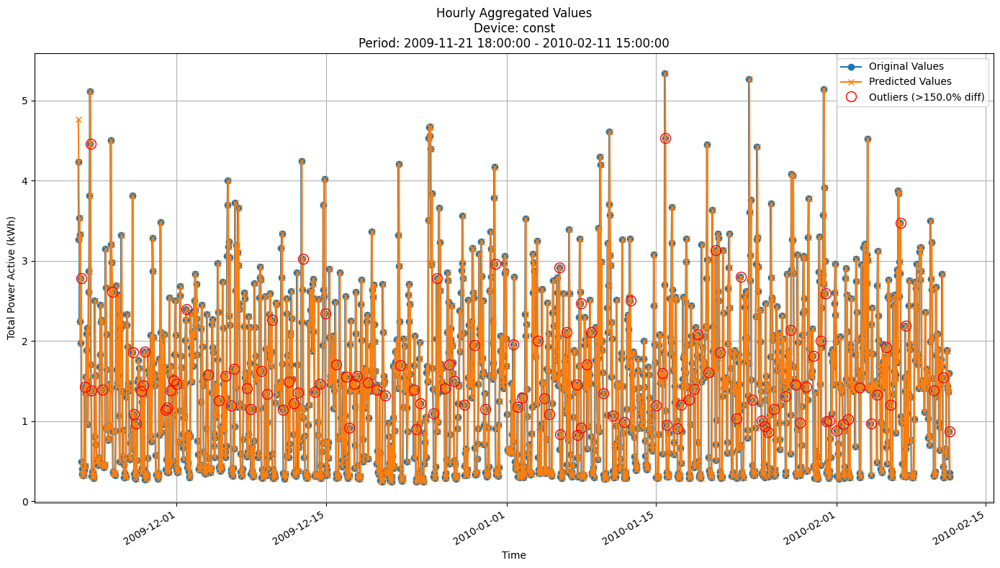


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.7250
MAE: 0.4930
MAPE: 43.3273%

Directional Metrics:
Directional Accuracy: 50.3817%
First-Diff Correlation: -0.0558

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [14]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in bl_prev_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, bl_prev_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, bl_prev_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5,
                            )

### GBDT

In [ ]:
update_freq = "14D"  # Update the model every 14 days

gbdt = GradientBoostingRegressor
gbdt_params = {'n_estimators': 25, 
               'learning_rate': 0.01, 
               'max_depth': 3, 
               'subsample': 0.8, 
               'random_state': 42}

In [16]:
gbdt_train_period_predictions, gbdt_valid_period_predictions, \
gbdt_train_period_metrics, gbdt_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=gbdt, 
    model_params=gbdt_params, 
    train=train, 
    valid=valid, 
    incremental=False,
    use_residuals=USE_RESIDUAL,
    data_freq=DATA_FREQUENCY, 
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/40 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2006-12-23 19:00:00+01:00 to 2007-01-20 17:00:00+01:00

Time: 0.06 seconds
Predicting for chunk from 2007-01-20 18:00:00+01:00 to 2007-02-03 18:00:00+01:00

-------------------------

Retraining model on data from 2006-12-23 19:00:00+01:00 to 2007-02-03 18:00:00+01:00

Time: 0.07 seconds
Predicting for chunk from 2007-02-03 19:00:00+01:00 to 2007-02-17 17:00:00+01:00

-------------------------
Model's memory usage: 0.008522 MB
Metrics for Device: const | Period: 2007-01-20 18:00:00+01:00 - 2007-02-17 17:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.8086
	MAE: 0.5533
	MAPE: 45.1562%

Directional Metrics:
	Directional Accuracy: 50.9687%
	First-Diff Correlation: 0.0006

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2006-12-23 19:00:00+01:00 to 2007-02-17 17:00:00+01:00

Time: 0.10 seconds
Predicting for chunk from 2007-02-17 18:00:00+01:00 to 2007-03-03 18:00:00+01:00

-------------------------

Retraining model on data from 2006-12-23 19:00:00+01:00 to 2007-03-03 18:00:00+01:00

Time: 0.12 seconds
Predicting for chunk from 2007-03-03 19:00:00+01:00 to 2007-03-17 17:00:00+01:00

-------------------------
Model's memory usage: 0.008446 MB
Metrics for Device: const | Period: 2007-02-17 18:00:00+01:00 - 2007-03-17 17:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.7213
	MAE: 0.4518
	MAPE: 48.9227%

Directional Metrics:
	Directional Accuracy: 46.6468%
	First-Diff Correlation: -0.0280

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (71 outputs left out)

Processing devices in split 38:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2006-12-23 19:00:00+01:00 to 2009-12-19 17:00:00+01:00

Time: 2.08 seconds
Predicting for chunk from 2009-12-19 18:00:00+01:00 to 2010-01-02 18:00:00+01:00

-------------------------

Retraining model on data from 2006-12-23 19:00:00+01:00 to 2010-01-02 18:00:00+01:00

Time: 2.00 seconds
Predicting for chunk from 2010-01-02 19:00:00+01:00 to 2010-01-16 17:00:00+01:00

-------------------------
Model's memory usage: 0.007759 MB
Metrics for Device: const | Period: 2009-12-19 18:00:00+01:00 - 2010-01-16 17:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.6745
	MAE: 0.4472
	MAPE: 40.1611%

Directional Metrics:
	Directional Accuracy: 51.5648%
	First-Diff Correlation: -0.0135

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta

Processing devices in split 39:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2006-12-23 19:00:00+01:00 to 2010-01-16 17:00:00+01:00

Time: 2.05 seconds
Predicting for chunk from 2010-01-16 18:00:00+01:00 to 2010-01-30 18:00:00+01:00

-------------------------

Retraining model on data from 2006-12-23 19:00:00+01:00 to 2010-01-30 18:00:00+01:00

Time: 2.06 seconds
Predicting for chunk from 2010-01-30 19:00:00+01:00 to 2010-02-11 15:00:00+01:00

-------------------------
Model's memory usage: 0.007759 MB
Metrics for Device: const | Period: 2010-01-16 18:00:00+01:00 - 2010-02-11 15:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.7193
	MAE: 0.4921
	MAPE: 40.4014%

Directional Metrics:
	Directional Accuracy: 52.4960%
	First-Diff Correlation: -0.0555

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.1111
		Recall: 0.1250
		F1: 0.1176

Delayed Detection (delta

#### Results

In [17]:
print("\n\nTrain period metrics:")
gbdt_all_time_train_metrics = all_time_aggregation_metrics(gbdt_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
gbdt_all_time_valid_metrics = all_time_aggregation_metrics(gbdt_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
# Hourly Metrics:
# 	RMSE: 0.2486 ± 0.0612
# 	MAE: 0.1594 ± 0.0516
# 	MAPE: 33.4958% ± 5.3587%

# 	Directional Metrics:
# 		Directional Accuracy: 62.4754% ± 7.1041%
# 		First-Diff Correlation: 0.3821 ± 0.0970

# 	Immediate Detection (delta=0):
# 		Spike Precision: 0.1544 ± 0.1193
# 		Spike Recall: 0.1617 ± 0.1297
# 		Spike F1: 0.1577 ± 0.1238
# 		Drop Precision: 0.1459 ± 0.0857
# 		Drop Recall: 0.1534 ± 0.0909
# 		Drop F1: 0.1493 ± 0.0879

# 	1-Hour Delayed Detection (delta=1):
# 		Spike Precision: 0.4691 ± 0.2714
# 		Spike Recall: 0.4908 ± 0.2907
# 		Spike F1: 0.4788 ± 0.2795
# 		Drop Precision: 0.2117 ± 0.1062
# 		Drop Recall: 0.2201 ± 0.1161
# 		Drop F1: 0.2153 ± 0.1100



Train period metrics:


Aggregated Metrics Across Periods
Device ID: const
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.7012 ± 0.0260
	MAE: 0.4540 ± 0.0239
	MAPE: 49.3148% ± 2.5282%

	Directional Metrics:
		Directional Accuracy: 49.8075% ± 0.6903%
		First-Diff Correlation: -0.0414 ± 0.0092

	Immediate Detection (delta=0):
		Spike Precision: 0.0124 ± 0.0058
		Spike Recall: 0.0129 ± 0.0060
		Spike F1: 0.0126 ± 0.0059
		Drop Precision: 0.0313 ± 0.0140
		Drop Recall: 0.0324 ± 0.0145
		Drop F1: 0.0318 ± 0.0142

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.9391 ± 0.0535
		Spike Recall: 0.9857 ± 0.0086
		Spike F1: 0.9609 ± 0.0302
		Drop Precision: 0.4845 ± 0.1502
		Drop Recall: 0.5007 ± 0.1544
		Drop F1: 0.4924 ± 0.1521
Daily Metrics:
	RMSE: 1.2336 ± 0.1330
	MAE: 0.9463 ± 0.1077
	MAPE: 4.1340% ± 0.2154%

	Directional Metrics:
		Directional Accuracy: 93.6975% ± 0.8092%
		First-Diff Correlation: 0.9820 ± 0.0029

	Immediate Detection (delta=0):
		Spi

#### Training plots

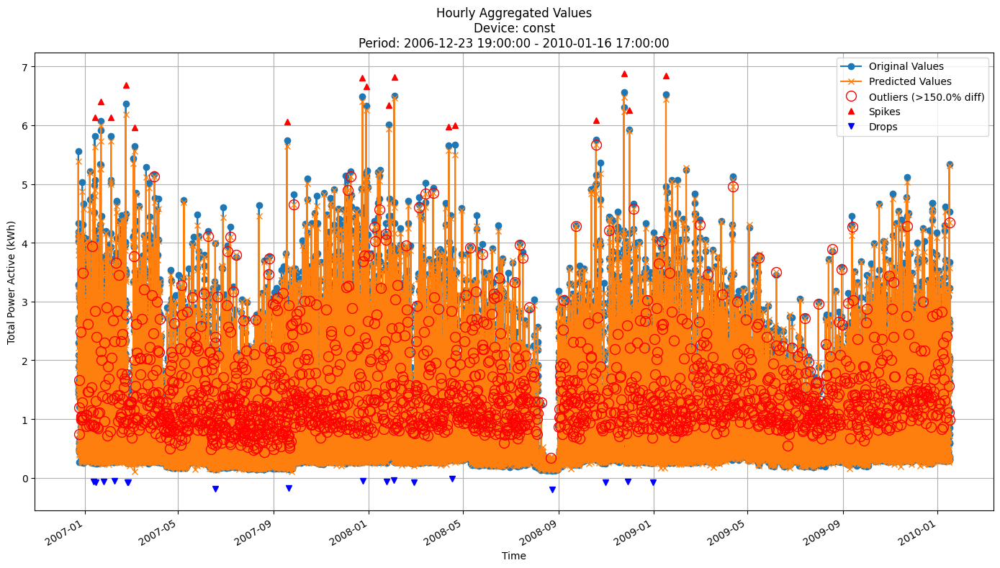


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.6705
MAE: 0.4322
MAPE: 47.8388%

Directional Metrics:
Directional Accuracy: 49.1108%
First-Diff Correlation: -0.0460

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8889
  Recall: 1.0000
  F1 Score: 0.9412
Drops:
  Precision: 0.0526
  Recall: 0.0588
  F1 Score: 0.0556


In [18]:
for device_id in gbdt_train_period_predictions.keys():
    y_train = gbdt_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = gbdt_train_period_predictions[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)
# 0.17, 0.12, 25.55, 70.81%, 0.72

#### Validation plots
Plot only the last few periods of predictions

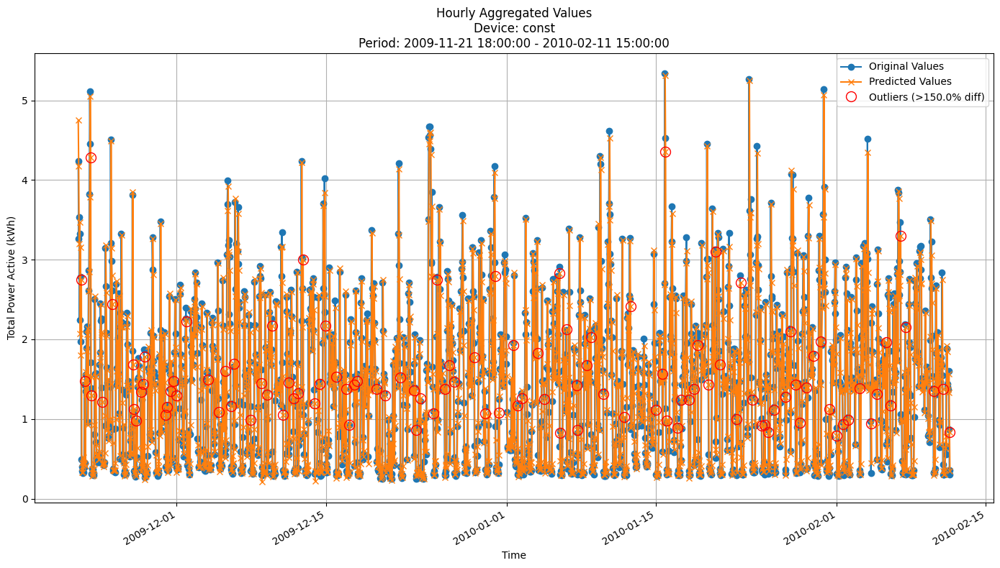


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.6975
MAE: 0.4723
MAPE: 41.3159%

Directional Metrics:
Directional Accuracy: 51.4504%
First-Diff Correlation: -0.0397

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [19]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in gbdt_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, gbdt_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, gbdt_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

# Basic Prediction Metrics:
# RMSE: 0.2195
# MAE: 0.1398
# MAPE: 33.6987%

### Random Forest model

In [ ]:
update_freq = "14D"  # Update the model every 14 days
rf = RandomForestRegressor
rf_params = {'n_estimators': 200, 
             'max_depth': 7, 
             'max_features': 0.7, 
             'random_state': 42, 
             'n_jobs': -1}  # Devashish

In [21]:
rf_train_period_predictions, rf_valid_period_predictions, \
rf_train_period_metrics, rf_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=rf, 
    model_params=rf_params, 
    train=train, 
    valid=valid, 
    use_residuals=USE_RESIDUAL,
    incremental=False,
    data_freq=DATA_FREQUENCY, 
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/40 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2006-12-23 19:00:00+01:00 to 2007-01-20 17:00:00+01:00

Time: 0.23 seconds
Predicting for chunk from 2007-01-20 18:00:00+01:00 to 2007-02-03 18:00:00+01:00

-------------------------

Retraining model on data from 2006-12-23 19:00:00+01:00 to 2007-02-03 18:00:00+01:00

Time: 0.22 seconds
Predicting for chunk from 2007-02-03 19:00:00+01:00 to 2007-02-17 17:00:00+01:00

-------------------------
Model's memory usage: 0.081039 MB
Metrics for Device: const | Period: 2007-01-20 18:00:00+01:00 - 2007-02-17 17:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.7706
	MAE: 0.5278
	MAPE: 46.2259%

Directional Metrics:
	Directional Accuracy: 55.4396%
	First-Diff Correlation: 0.0470

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2006-12-23 19:00:00+01:00 to 2007-02-17 17:00:00+01:00

Time: 0.22 seconds
Predicting for chunk from 2007-02-17 18:00:00+01:00 to 2007-03-03 18:00:00+01:00

-------------------------

Retraining model on data from 2006-12-23 19:00:00+01:00 to 2007-03-03 18:00:00+01:00

Time: 0.22 seconds
Predicting for chunk from 2007-03-03 19:00:00+01:00 to 2007-03-17 17:00:00+01:00

-------------------------
Model's memory usage: 0.081032 MB
Metrics for Device: const | Period: 2007-02-17 18:00:00+01:00 - 2007-03-17 17:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.7091
	MAE: 0.5018
	MAPE: 76.0626%

Directional Metrics:
	Directional Accuracy: 51.4158%
	First-Diff Correlation: 0.0162

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0556
		Recall: 0.0500
		F1: 0.0526
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (71 outputs left out)

Processing devices in split 38:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2006-12-23 19:00:00+01:00 to 2009-12-19 17:00:00+01:00

Time: 2.18 seconds
Predicting for chunk from 2009-12-19 18:00:00+01:00 to 2010-01-02 18:00:00+01:00

-------------------------

Retraining model on data from 2006-12-23 19:00:00+01:00 to 2010-01-02 18:00:00+01:00

Time: 2.32 seconds
Predicting for chunk from 2010-01-02 19:00:00+01:00 to 2010-01-16 17:00:00+01:00

-------------------------
Model's memory usage: 0.081032 MB
Metrics for Device: const | Period: 2009-12-19 18:00:00+01:00 - 2010-01-16 17:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.6219
	MAE: 0.4233
	MAPE: 41.2291%

Directional Metrics:
	Directional Accuracy: 52.9061%
	First-Diff Correlation: 0.0600

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=

Processing devices in split 39:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2006-12-23 19:00:00+01:00 to 2010-01-16 17:00:00+01:00

Time: 2.24 seconds
Predicting for chunk from 2010-01-16 18:00:00+01:00 to 2010-01-30 18:00:00+01:00

-------------------------

Retraining model on data from 2006-12-23 19:00:00+01:00 to 2010-01-30 18:00:00+01:00

Time: 2.15 seconds
Predicting for chunk from 2010-01-30 19:00:00+01:00 to 2010-02-11 15:00:00+01:00

-------------------------
Model's memory usage: 0.081032 MB
Metrics for Device: const | Period: 2010-01-16 18:00:00+01:00 - 2010-02-11 15:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.6385
	MAE: 0.4483
	MAPE: 37.4057%

Directional Metrics:
	Directional Accuracy: 53.1401%
	First-Diff Correlation: 0.0519

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0833
		Recall: 0.1250
		F1: 0.1000

Delayed Detection (delta=

#### Results

In [22]:
print("\n\nTrain period metrics:")
rf_all_time_train_metrics = all_time_aggregation_metrics(rf_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
rf_all_time_valid_metrics = all_time_aggregation_metrics(rf_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)

# Best values:
# Hourly Metrics:
# 	RMSE: 0.2221 ± 0.0148
# 	MAE: 0.1267 ± 0.0092
# 	MAPE: 22.1472% ± 2.0063%

# 	Directional Metrics:
# 		Directional Accuracy: 60.8511% ± 2.9815%
# 		First-Diff Correlation: 0.4859 ± 0.0565

# 	Immediate Detection (delta=0):
# 		Spike Precision: 0.2094 ± 0.0638
# 		Spike Recall: 0.1844 ± 0.0780
# 		Spike F1: 0.1927 ± 0.0741
# 		Drop Precision: 0.0547 ± 0.0125
# 		Drop Recall: 0.1408 ± 0.0536
# 		Drop F1: 0.0779 ± 0.0216

# 	1-Hour Delayed Detection (delta=1):
# 		Spike Precision: 0.4647 ± 0.0473
# 		Spike Recall: 0.3984 ± 0.1023
# 		Spike F1: 0.4191 ± 0.0799
# 		Drop Precision: 0.1104 ± 0.0172
# 		Drop Recall: 0.2821 ± 0.0884
# 		Drop F1: 0.1571 ± 0.0324



Train period metrics:


Aggregated Metrics Across Periods
Device ID: const
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.5934 ± 0.0189
	MAE: 0.4012 ± 0.0098
	MAPE: 49.1464% ± 4.2475%

	Directional Metrics:
		Directional Accuracy: 53.6528% ± 1.9569%
		First-Diff Correlation: 0.1109 ± 0.0631

	Immediate Detection (delta=0):
		Spike Precision: 0.1304 ± 0.1403
		Spike Recall: 0.1258 ± 0.0813
		Spike F1: 0.1241 ± 0.0913
		Drop Precision: 0.0665 ± 0.0271
		Drop Recall: 0.0639 ± 0.0251
		Drop F1: 0.0651 ± 0.0260

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.8114 ± 0.1043
		Spike Recall: 0.8142 ± 0.0707
		Spike F1: 0.8038 ± 0.0555
		Drop Precision: 0.2540 ± 0.0873
		Drop Recall: 0.2462 ± 0.0783
		Drop F1: 0.2497 ± 0.0824
Daily Metrics:
	RMSE: 1.9936 ± 0.0668
	MAE: 1.5729 ± 0.0675
	MAPE: 7.8300% ± 0.8218%

	Directional Metrics:
		Directional Accuracy: 93.2395% ± 0.8203%
		First-Diff Correlation: 0.9850 ± 0.0029

	Immediate Detection (delta=0):
		Spik

#### Training plots
Plot only the last period of predictions

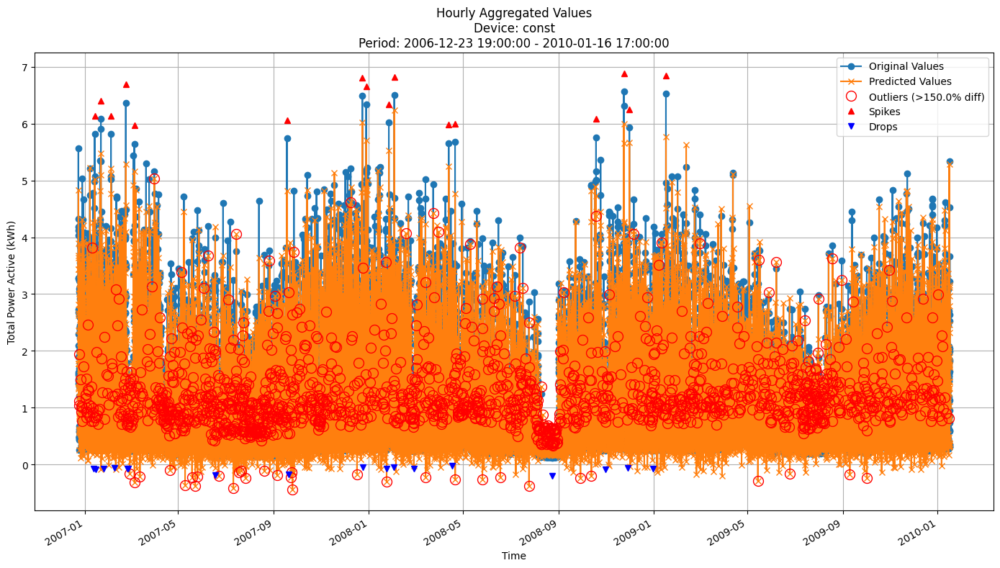


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.5923
MAE: 0.3959
MAPE: 48.3661%

Directional Metrics:
Directional Accuracy: 51.8268%
First-Diff Correlation: 0.0656

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7222
  Recall: 0.8125
  F1 Score: 0.7647
Drops:
  Precision: 0.0556
  Recall: 0.0588
  F1 Score: 0.0571


In [23]:
for device_id in rf_train_period_predictions.keys():
    y_train = rf_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = rf_train_period_predictions[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last periods of predictions

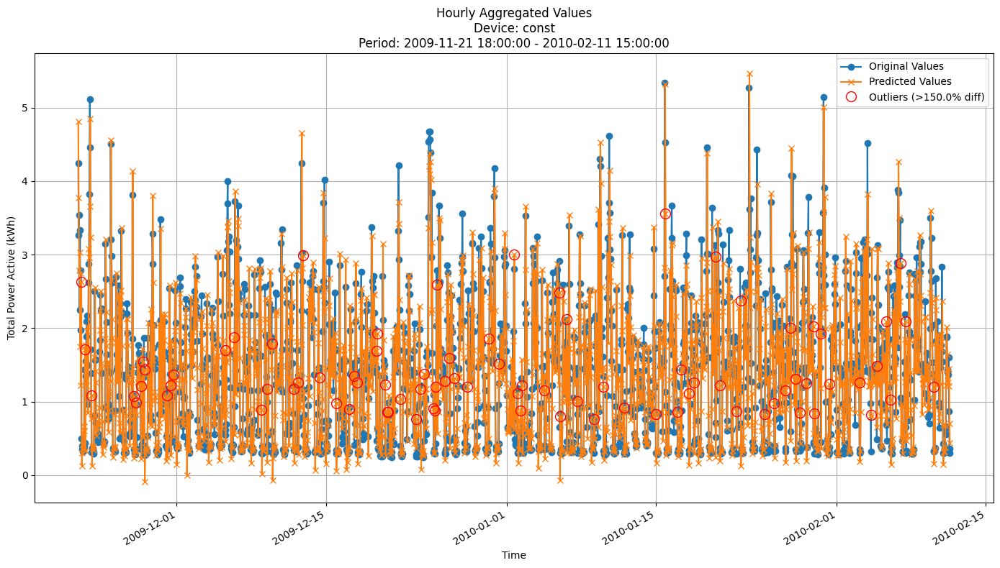


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.6237
MAE: 0.4322
MAPE: 39.3949%

Directional Metrics:
Directional Accuracy: 52.7226%
First-Diff Correlation: 0.0615

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [24]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in rf_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, rf_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, rf_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### Hoeffding Tree

In [ ]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

hoef = HoeffdingTreeRegressor
hoef_params = {'max_depth': 3, 
               'grace_period': 10, 
               'tau': 0.005, 
               'delta': 0.05, 
               'leaf_prediction': 'mean'}  # Devashish


In [26]:

hoef_all_train_preds, hoef_all_valid_preds, \
hoef_all_train_metrics, hoef_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=hoef, 
    model_params=hoef_params, 
    train=train, 
    valid=valid, 
    use_residuals=USE_RESIDUAL,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/40 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 15
Filtered feature count: 15
Excluded lag features: None
Initial training on data from 2006-12-23 19:00:00+01:00 to 2007-01-20 17:00:00+01:00
Model's memory usage: 0.043091 MB
Metrics for Device: const | Period: 2007-01-20 18:00:00+01:00 - 2007-02-17 17:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.8233
	MAE: 0.5772
	MAPE: 49.1599%

Directional Metrics:
	Directional Accuracy: 50.9687%
	First-Diff Correlation: -0.0037

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.6667
		Recall: 0.6667
		F1: 0.6667
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------


Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 15
Filtered feature count: 15
Excluded lag features: None
Initial training on data from 2006-12-23 19:00:00+01:00 to 2007-02-17 17:00:00+01:00
Model's memory usage: 0.047531 MB
Metrics for Device: const | Period: 2007-02-17 18:00:00+01:00 - 2007-03-17 17:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.7300
	MAE: 0.4619
	MAPE: 50.5718%

Directional Metrics:
	Directional Accuracy: 44.1133%
	First-Diff Correlation: -0.0372

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.7600
		Recall: 0.9500
		F1: 0.8444
	Drops:
		Precision: 0.5417
		Recall: 0.6190
		F1: 0.5778
--------------------------------------------------


Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (71 outputs left out)

Processing devices in split 38:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 15
Filtered feature count: 15
Excluded lag features: None
Initial training on data from 2006-12-23 19:00:00+01:00 to 2009-12-19 17:00:00+01:00
Model's memory usage: 0.018158 MB
Metrics for Device: const | Period: 2009-12-19 18:00:00+01:00 - 2010-01-16 17:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.6865
	MAE: 0.4654
	MAPE: 43.6521%

Directional Metrics:
	Directional Accuracy: 51.4158%
	First-Diff Correlation: -0.0181

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 0.3333
		F1: 0.5000
	Drops:
		Precision: 1.0000
		Recall: 0.2000
		F1: 0.3333
--------------------------------------------------


Processing devices in split 39:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 15
Filtered feature count: 15
Excluded lag features: None
Initial training on data from 2006-12-23 19:00:00+01:00 to 2010-01-16 17:00:00+01:00
Model's memory usage: 0.018158 MB
Metrics for Device: const | Period: 2010-01-16 18:00:00+01:00 - 2010-02-11 15:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.7467
	MAE: 0.5183
	MAPE: 43.9961%

Directional Metrics:
	Directional Accuracy: 49.5974%
	First-Diff Correlation: -0.0683

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.9000
		Recall: 1.0000
		F1: 0.9474
	Drops:
		Precision: 0.4444
		Recall: 0.5000
		F1: 0.4706
--------------------------------------------------


#### Results

In [27]:
print("\n\nTrain period metrics:")
hoef_all_time_train_metrics = all_time_aggregation_metrics(hoef_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
hoef_all_time_valid_metrics = all_time_aggregation_metrics(hoef_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: const
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.7169 ± 0.0245
	MAE: 0.4684 ± 0.0245
	MAPE: 51.2711% ± 2.3305%

	Directional Metrics:
		Directional Accuracy: 48.4203% ± 0.6086%
		First-Diff Correlation: -0.0460 ± 0.0096

	Immediate Detection (delta=0):
		Spike Precision: 0.0207 ± 0.0093
		Spike Recall: 0.0218 ± 0.0100
		Spike F1: 0.0212 ± 0.0096
		Drop Precision: 0.0163 ± 0.0085
		Drop Recall: 0.0169 ± 0.0088
		Drop F1: 0.0166 ± 0.0086

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.9153 ± 0.0638
		Spike Recall: 0.9783 ± 0.0140
		Spike F1: 0.9445 ± 0.0383
		Drop Precision: 0.6153 ± 0.1910
		Drop Recall: 0.6420 ± 0.1943
		Drop F1: 0.6282 ± 0.1926
Daily Metrics:
	RMSE: 1.3199 ± 0.1714
	MAE: 0.9956 ± 0.1403
	MAPE: 4.0458% ± 0.3204%

	Directional Metrics:
		Directional Accuracy: 93.6535% ± 0.7615%
		First-Diff Correlation: 0.9800 ± 0.0034

	Immediate Detection (delta=0):
		Spi

#### Training plots
Plot only the last period of predictions

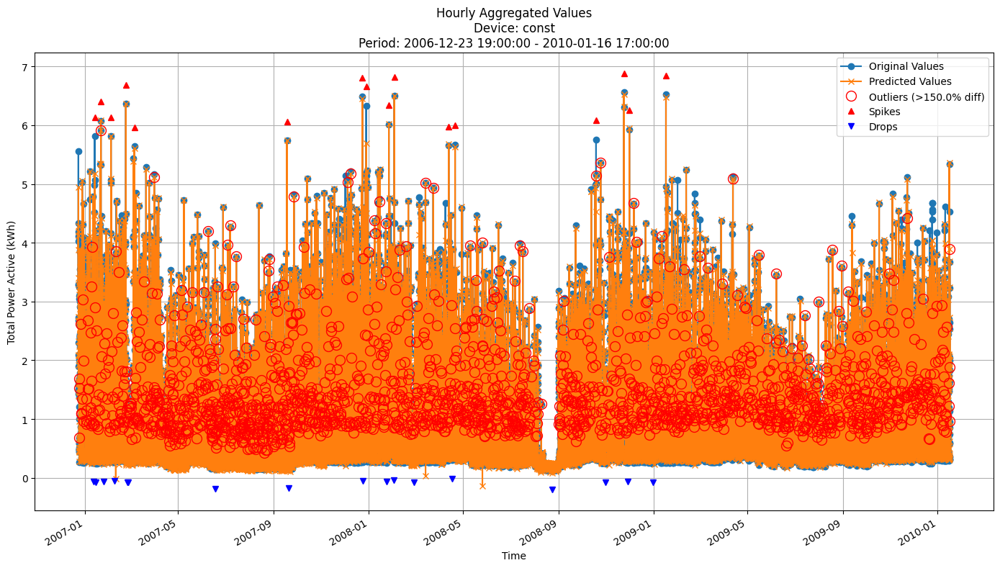


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.6873
MAE: 0.4460
MAPE: 49.3661%

Directional Metrics:
Directional Accuracy: 47.8570%
First-Diff Correlation: -0.0520

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8750
  Recall: 0.8750
  F1 Score: 0.8750
Drops:
  Precision: 0.1250
  Recall: 0.1176
  F1 Score: 0.1212


In [28]:
for device_id in hoef_all_train_preds.keys():
    y_train = hoef_all_train_preds[device_id][-1]['y_true']
    y_pred_train = hoef_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

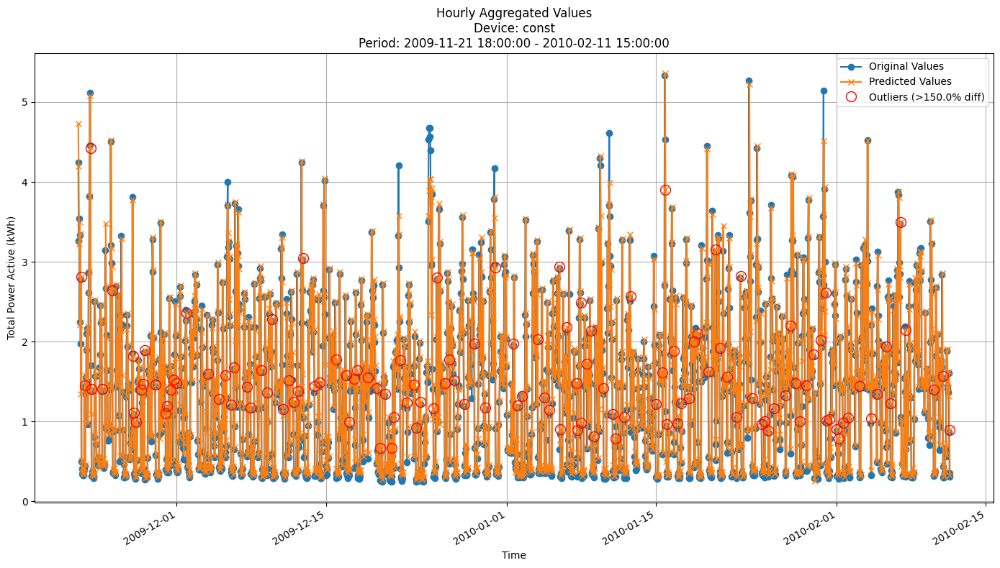


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.7181
MAE: 0.4933
MAPE: 44.7656%

Directional Metrics:
Directional Accuracy: 49.6183%
First-Diff Correlation: -0.0473

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [29]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in hoef_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, hoef_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, hoef_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (Hoeffding Tree)

In [ ]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

arf_hf = ARFRegressor
arf_hf_params = dict(n_models=10, 
                     max_features=0.8, 
                     aggregation_method='median', 
                     grace_period=10, 
                     max_depth=10, 
                     delta=0.5, 
                     tau=0.01, 
                     seed=42)  # NOT TUNED


In [31]:
arf_hf_all_train_preds, arf_hf_all_valid_preds, \
arf_hf_all_train_metrics, arf_hf_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=arf_hf,
    model_params=arf_hf_params,
    train=train,
    valid=valid,
    use_residuals=USE_RESIDUAL,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/40 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 15
Filtered feature count: 15
Excluded lag features: None
Initial training on data from 2006-12-23 19:00:00+01:00 to 2007-01-20 17:00:00+01:00
Model's memory usage: 8.116142 MB
Metrics for Device: const | Period: 2007-01-20 18:00:00+01:00 - 2007-02-17 17:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.7897
	MAE: 0.5528
	MAPE: 48.7942%

Directional Metrics:
	Directional Accuracy: 55.7377%
	First-Diff Correlation: 0.0055

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.5000
		Recall: 1.0000
		F1: 0.6667
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
D

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 15
Filtered feature count: 15
Excluded lag features: None
Initial training on data from 2006-12-23 19:00:00+01:00 to 2007-02-17 17:00:00+01:00
Model's memory usage: 9.957634 MB
Metrics for Device: const | Period: 2007-02-17 18:00:00+01:00 - 2007-03-17 17:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.7133
	MAE: 0.4808
	MAPE: 60.7327%

Directional Metrics:
	Directional Accuracy: 50.6706%
	First-Diff Correlation: -0.0278

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.6786
		Recall: 0.9500
		F1: 0.7917
	Drops:
		Precision: 0.2593
		Recall: 0.3333
		F1: 0.2917
--------------------------------------------------


Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (71 outputs left out)

Processing devices in split 38:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 15
Filtered feature count: 15
Excluded lag features: None
Initial training on data from 2006-12-23 19:00:00+01:00 to 2009-12-19 17:00:00+01:00
Model's memory usage: 21.787186 MB
Metrics for Device: const | Period: 2009-12-19 18:00:00+01:00 - 2010-01-16 17:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.6660
	MAE: 0.4497
	MAPE: 43.8882%

Directional Metrics:
	Directional Accuracy: 55.4396%
	First-Diff Correlation: -0.0193

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.7143
		Recall: 0.8333
		F1: 0.7692
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------

Processing devices in split 39:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 15
Filtered feature count: 15
Excluded lag features: None
Initial training on data from 2006-12-23 19:00:00+01:00 to 2010-01-16 17:00:00+01:00
Model's memory usage: 22.078949 MB
Metrics for Device: const | Period: 2010-01-16 18:00:00+01:00 - 2010-02-11 15:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.7084
	MAE: 0.4977
	MAPE: 43.0179%

Directional Metrics:
	Directional Accuracy: 50.5636%
	First-Diff Correlation: -0.0582

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.8182
		Recall: 1.0000
		F1: 0.9000
	Drops:
		Precision: 0.2000
		Recall: 0.2500
		F1: 0.2222
--------------------------------------------------

#### Results

In [32]:
print("\n\nTrain period metrics:")
arf_hf_all_time_train_metrics = all_time_aggregation_metrics(arf_hf_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
arf_hf_all_time_valid_metrics = all_time_aggregation_metrics(arf_hf_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: const
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.6690 ± 0.0166
	MAE: 0.4457 ± 0.0175
	MAPE: 52.8263% ± 3.1321%

	Directional Metrics:
		Directional Accuracy: 51.3543% ± 1.3213%
		First-Diff Correlation: -0.0073 ± 0.0175

	Immediate Detection (delta=0):
		Spike Precision: 0.0500 ± 0.0204
		Spike Recall: 0.0593 ± 0.0296
		Spike F1: 0.0541 ± 0.0238
		Drop Precision: 0.0534 ± 0.0197
		Drop Recall: 0.0615 ± 0.0224
		Drop F1: 0.0571 ± 0.0210

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.7838 ± 0.0880
		Spike Recall: 0.9454 ± 0.0212
		Spike F1: 0.8531 ± 0.0559
		Drop Precision: 0.3324 ± 0.1132
		Drop Recall: 0.3832 ± 0.1235
		Drop F1: 0.3557 ± 0.1182
Daily Metrics:
	RMSE: 1.7168 ± 0.1066
	MAE: 1.3660 ± 0.0878
	MAPE: 6.6218% ± 0.5109%

	Directional Metrics:
		Directional Accuracy: 93.0586% ± 0.8187%
		First-Diff Correlation: 0.9820 ± 0.0031

	Immediate Detection (delta=0):
		Spi

#### Training plots

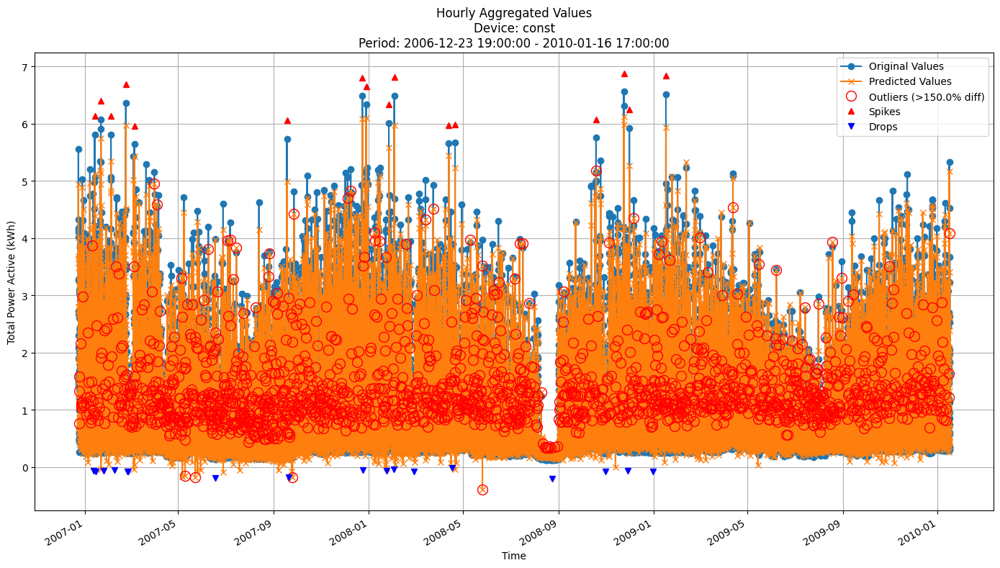


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.6485
MAE: 0.4293
MAPE: 50.9933%

Directional Metrics:
Directional Accuracy: 50.3088%
First-Diff Correlation: -0.0244

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.5926
  Recall: 1.0000
  F1 Score: 0.7442
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [33]:
for device_id in arf_hf_all_train_preds.keys():
    y_train = arf_hf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_hf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

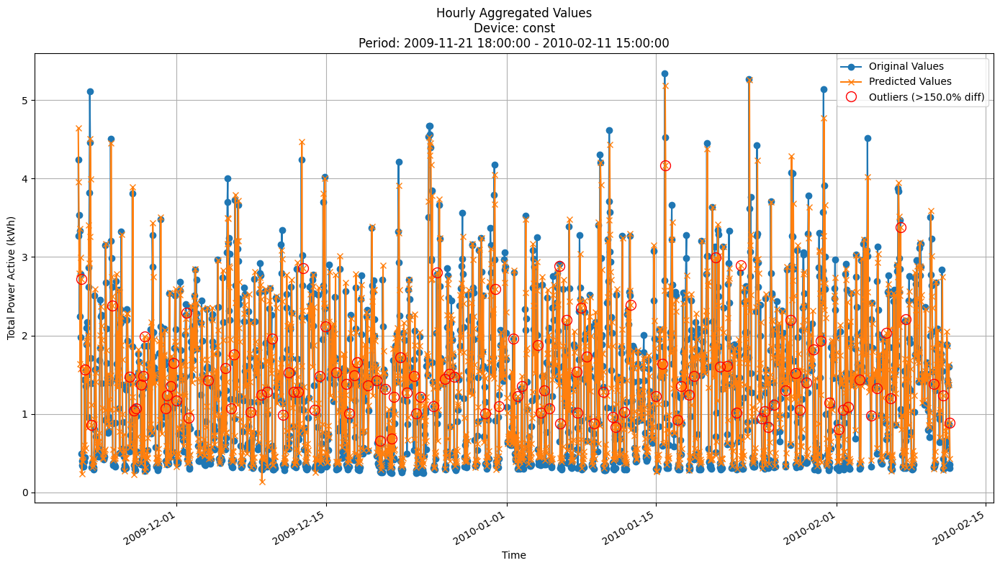


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.6878
MAE: 0.4746
MAPE: 44.1017%

Directional Metrics:
Directional Accuracy: 52.4682%
First-Diff Correlation: -0.0434

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [34]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in arf_hf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_hf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_hf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

### FastODT

In [ ]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

fodt = fastodt.FastODT

fodt_params = {'depth': 5, 
 'grace_period': 10, 
 'grace_period_depth': -1, 
 'split_confidence': 0.001, 
 'max_feature': 0.7, 
 'tie_threshold': 0.01, 
 'bin_type': 'adaptive', 
 'max_bins': 8, 
 'split_criterion': 'vr_rel'
}  # Devashish

In [36]:
fodt_all_train_preds, fodt_all_valid_preds, \
fodt_all_train_metrics, fodt_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=fodt, 
    model_params=fodt_params, 
    train=train, 
    valid=valid, 
    use_residuals=USE_RESIDUAL,
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/40 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 15
Filtered feature count: 15
Excluded lag features: None
Initial training on data from 2006-12-23 19:00:00+01:00 to 2007-01-20 17:00:00+01:00
Model's memory usage: 0.030777 MB
Metrics for Device: const | Period: 2007-01-20 18:00:00+01:00 - 2007-02-17 17:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.8266
	MAE: 0.5666
	MAPE: 45.7414%

Directional Metrics:
	Directional Accuracy: 50.3726%
	First-Diff Correlation: -0.0129

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------


Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 15
Filtered feature count: 15
Excluded lag features: None
Initial training on data from 2006-12-23 19:00:00+01:00 to 2007-02-17 17:00:00+01:00
Model's memory usage: 0.029556 MB
Metrics for Device: const | Period: 2007-02-17 18:00:00+01:00 - 2007-03-17 17:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.7397
	MAE: 0.4518
	MAPE: 45.0602%

Directional Metrics:
	Directional Accuracy: 44.2623%
	First-Diff Correlation: -0.0331

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 0.9048
		F1: 0.9500
--------------------------------------------------


Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (71 outputs left out)

Processing devices in split 38:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 15
Filtered feature count: 15
Excluded lag features: None
Initial training on data from 2006-12-23 19:00:00+01:00 to 2009-12-19 17:00:00+01:00
Model's memory usage: 0.032715 MB
Metrics for Device: const | Period: 2009-12-19 18:00:00+01:00 - 2010-01-16 17:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.6979
	MAE: 0.4648
	MAPE: 41.6344%

Directional Metrics:
	Directional Accuracy: 52.0119%
	First-Diff Correlation: -0.0275

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------


Processing devices in split 39:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 15
Filtered feature count: 15
Excluded lag features: None
Initial training on data from 2006-12-23 19:00:00+01:00 to 2010-01-16 17:00:00+01:00
Model's memory usage: 0.031204 MB
Metrics for Device: const | Period: 2010-01-16 18:00:00+01:00 - 2010-02-11 15:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.7493
	MAE: 0.5165
	MAPE: 42.6238%

Directional Metrics:
	Directional Accuracy: 50.7246%
	First-Diff Correlation: -0.0721

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------


#### Results

In [37]:
print("\n\nTrain period metrics:")
fodt_all_time_train_metrics = all_time_aggregation_metrics(fodt_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
fodt_all_time_valid_metrics = all_time_aggregation_metrics(fodt_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: const
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.7251 ± 0.0272
	MAE: 0.4697 ± 0.0246
	MAPE: 50.1730% ± 2.5796%

	Directional Metrics:
		Directional Accuracy: 48.2223% ± 0.6369%
		First-Diff Correlation: -0.0554 ± 0.0091

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 1.0000 ± 0.0000
		Spike Recall: 0.9998 ± 0.0012
		Spike F1: 0.9999 ± 0.0006
		Drop Precision: 1.0000 ± 0.0000
		Drop Recall: 0.9996 ± 0.0013
		Drop F1: 0.9998 ± 0.0007
Daily Metrics:
	RMSE: 1.2252 ± 0.1561
	MAE: 0.9158 ± 0.1404
	MAPE: 3.4410% ± 0.2807%

	Directional Metrics:
		Directional Accuracy: 94.0693% ± 0.8891%
		First-Diff Correlation: 0.9807 ± 0.0033

	Immediate Detection (delta=0):
		Spi

#### Training plots


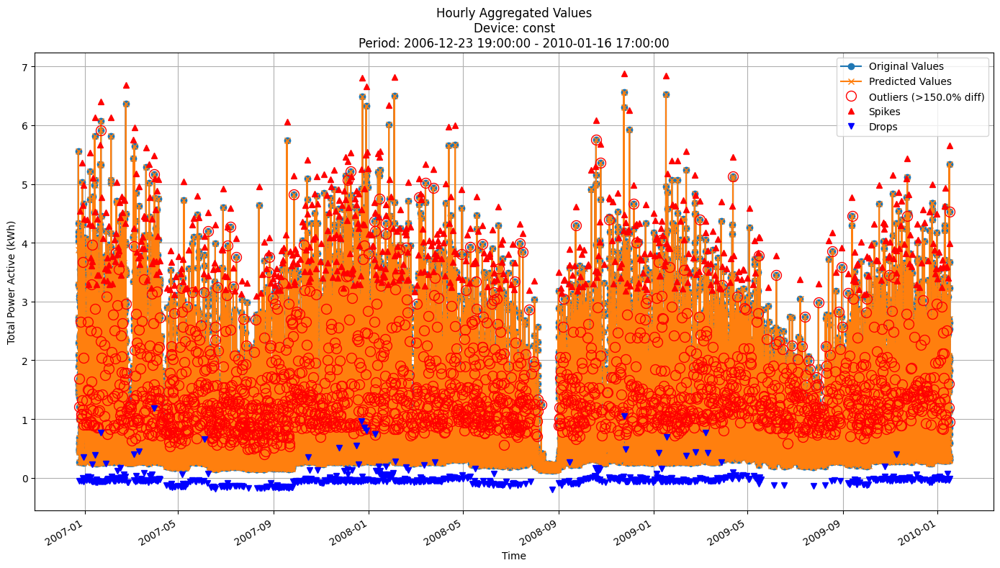


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.6937
MAE: 0.4476
MAPE: 48.8249%

Directional Metrics:
Directional Accuracy: 47.6449%
First-Diff Correlation: -0.0600

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 0.9984
  F1 Score: 0.9992
Drops:
  Precision: 1.0000
  Recall: 0.9984
  F1 Score: 0.9992


In [38]:
for device_id in fodt_all_train_preds.keys():
    y_train = fodt_all_train_preds[device_id][-1]['y_true']
    y_pred_train = fodt_all_train_preds[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id,
                            spike_prominence=SPIKE_PROMINENCE, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

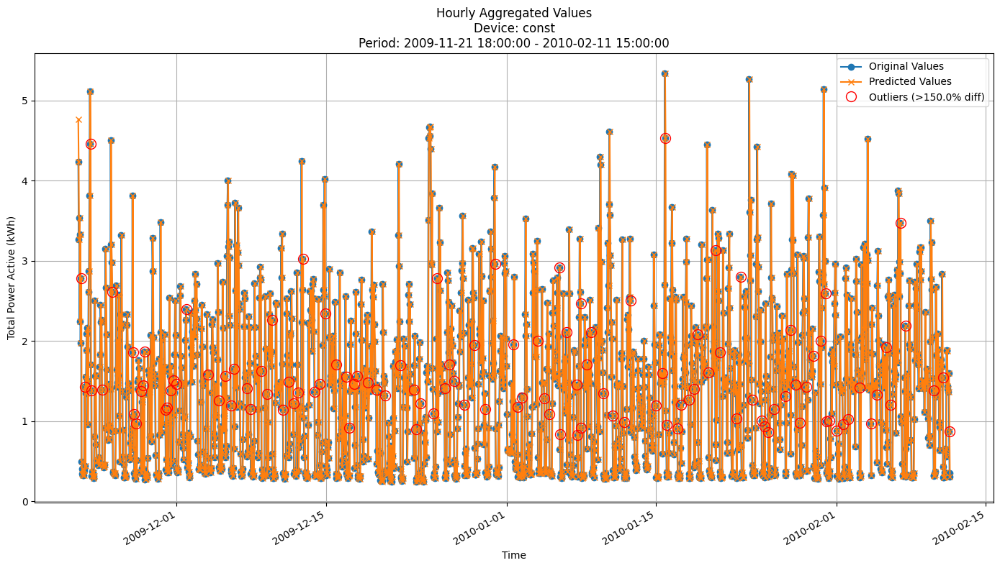


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.7250
MAE: 0.4930
MAPE: 43.3252%

Directional Metrics:
Directional Accuracy: 50.3817%
First-Diff Correlation: -0.0558

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [39]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in fodt_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, fodt_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, fodt_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (FastODT)

In [ ]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

arf = ARFRegressorFODT
arf_params = dict(n_models=20, 
                  aggregation_method="mean", 
                  grace_period=0,  # by default works for all leaves
                  disable_weighted_vote=True,
                  max_depth=10, 
                  delta=0.005, 
                  tau=0.01,
                  max_features=0.7, 
                  bin_type='adaptive', 
                  max_bins=8,
                  split_criterion='vr_rel',
                  seed=42, )  # NOT TUNED


In [41]:
arf_all_train_preds, arf_all_valid_preds, \
arf_all_train_metrics, arf_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=arf,
    model_params=arf_params,
    train=train,
    valid=valid,
    use_residuals=USE_RESIDUAL,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/40 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 15
Filtered feature count: 15
Excluded lag features: None
Initial training on data from 2006-12-23 19:00:00+01:00 to 2007-01-20 17:00:00+01:00
Model's memory usage: 0.830925 MB
Metrics for Device: const | Period: 2007-01-20 18:00:00+01:00 - 2007-02-17 17:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.8266
	MAE: 0.5666
	MAPE: 45.7495%

Directional Metrics:
	Directional Accuracy: 50.3726%
	First-Diff Correlation: -0.0129

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------


Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 15
Filtered feature count: 15
Excluded lag features: None
Initial training on data from 2006-12-23 19:00:00+01:00 to 2007-02-17 17:00:00+01:00
Model's memory usage: 0.841759 MB
Metrics for Device: const | Period: 2007-02-17 18:00:00+01:00 - 2007-03-17 17:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.7397
	MAE: 0.4518
	MAPE: 45.0616%

Directional Metrics:
	Directional Accuracy: 44.2623%
	First-Diff Correlation: -0.0331

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 0.9048
		F1: 0.9500
--------------------------------------------------


Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (71 outputs left out)

Processing devices in split 38:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 15
Filtered feature count: 15
Excluded lag features: None
Initial training on data from 2006-12-23 19:00:00+01:00 to 2009-12-19 17:00:00+01:00
Model's memory usage: 2.473412 MB
Metrics for Device: const | Period: 2009-12-19 18:00:00+01:00 - 2010-01-16 17:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.6912
	MAE: 0.4759
	MAPE: 45.4726%

Directional Metrics:
	Directional Accuracy: 52.4590%
	First-Diff Correlation: -0.0180

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.8571
		Recall: 1.0000
		F1: 0.9231
	Drops:
		Precision: 0.5000
		Recall: 0.6000
		F1: 0.5455
--------------------------------------------------


Processing devices in split 39:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 15
Filtered feature count: 15
Excluded lag features: None
Initial training on data from 2006-12-23 19:00:00+01:00 to 2010-01-16 17:00:00+01:00
Model's memory usage: 2.524498 MB
Metrics for Device: const | Period: 2010-01-16 18:00:00+01:00 - 2010-02-11 15:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.7217
	MAE: 0.5288
	MAPE: 48.7803%

Directional Metrics:
	Directional Accuracy: 50.4026%
	First-Diff Correlation: -0.0492

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 0.7778
		F1: 0.8750
	Drops:
		Precision: 0.3333
		Recall: 0.2500
		F1: 0.2857
--------------------------------------------------


#### Results

In [42]:
print("\n\nTrain period metrics:")
arf_all_time_train_metrics = all_time_aggregation_metrics(arf_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
arf_all_time_valid_metrics = all_time_aggregation_metrics(arf_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: const
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.7244 ± 0.0282
	MAE: 0.4701 ± 0.0244
	MAPE: 50.4759% ± 3.0774%

	Directional Metrics:
		Directional Accuracy: 48.2185% ± 0.6408%
		First-Diff Correlation: -0.0549 ± 0.0094

	Immediate Detection (delta=0):
		Spike Precision: 0.0003 ± 0.0021
		Spike Recall: 0.0004 ± 0.0028
		Spike F1: 0.0004 ± 0.0024
		Drop Precision: 0.0005 ± 0.0033
		Drop Recall: 0.0007 ± 0.0043
		Drop F1: 0.0006 ± 0.0037

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.9934 ± 0.0415
		Spike Recall: 0.9989 ± 0.0056
		Spike F1: 0.9958 ± 0.0260
		Drop Precision: 0.9872 ± 0.0797
		Drop Recall: 0.9907 ± 0.0559
		Drop F1: 0.9887 ± 0.0694
Daily Metrics:
	RMSE: 1.2534 ± 0.2189
	MAE: 0.9419 ± 0.2006
	MAPE: 3.6298% ± 1.1603%

	Directional Metrics:
		Directional Accuracy: 94.0671% ± 0.8893%
		First-Diff Correlation: 0.9806 ± 0.0033

	Immediate Detection (delta=0):
		Spi

#### Training plots

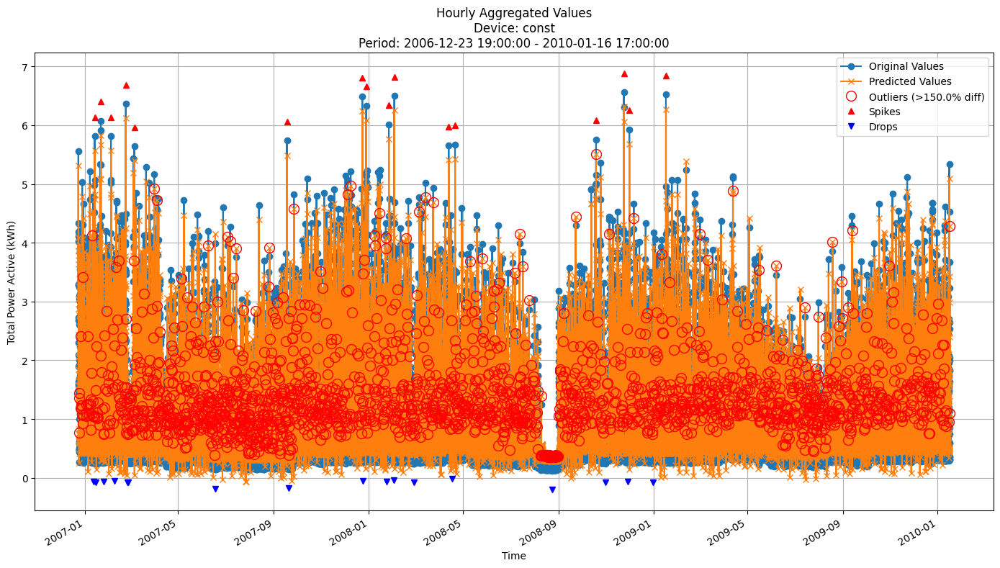


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.6690
MAE: 0.4652
MAPE: 61.0598%

Directional Metrics:
Directional Accuracy: 47.4924%
First-Diff Correlation: -0.0412

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.3556
  Recall: 1.0000
  F1 Score: 0.5246
Drops:
  Precision: 0.0444
  Recall: 0.1176
  F1 Score: 0.0645


In [43]:
for device_id in arf_all_train_preds.keys():
    y_train = arf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

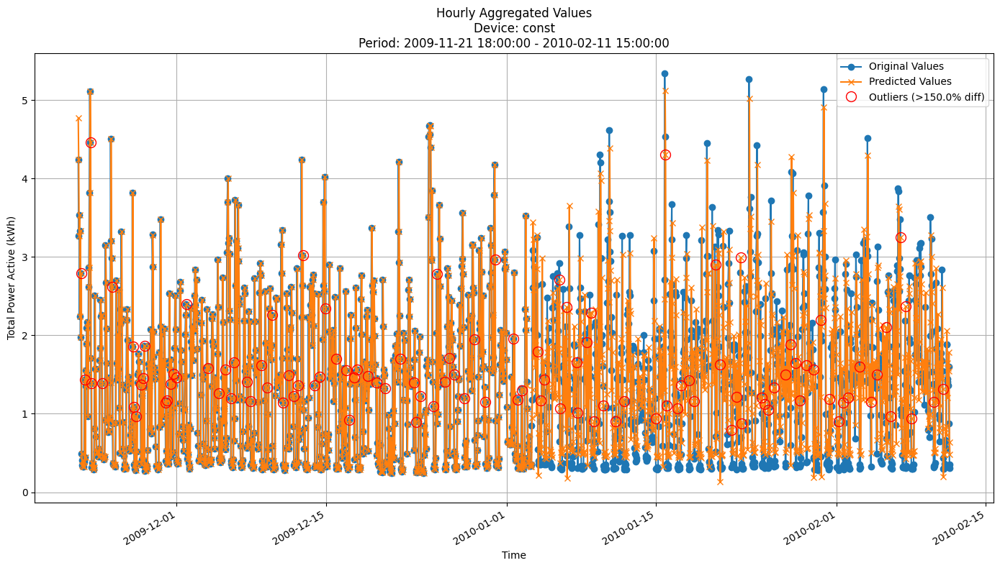


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.7139
MAE: 0.5006
MAPE: 46.5843%

Directional Metrics:
Directional Accuracy: 50.4835%
First-Diff Correlation: -0.0445

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [44]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in arf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

### iNcubation Boost

In [ ]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario:

split_confidence_hf = 0.01
grace_period = 24
depth = 50
eagerness = 0
bin_type = 'mean'  # 'mean' or 'adaptive'
max_bins = 1
# max_bins = 32  # for adaptive binning
max_features = 0.7
tie_threshold = 0.05
grace_period_depth = -1 # set to 1 to use only for first node, set to -1 to use for all nodes, set to N to use for N nodes

incb = IncubationBoost
incb_params = {'length': 30, 
               'learning_rate': 0.1, 
               'depth': 5, 
               'grace_period': 48, 
               'grace_period_depth': 1, 
               'split_confidence': 0.01, 
               'max_feature': 0.3, 
               'tie_threshold': 0.01, 
               'bin_type': 'adaptive', 
               'max_bins': 16, 
               'split_criterion': 'vr_rel', 
               'random_state': 42,
               'verbose': False}  # Devashish

In [46]:
incb_all_train_preds, incb_all_valid_preds, \
incb_all_train_metrics, incb_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=incb, 
    model_params=incb_params, 
    train=train, 
    valid=valid, 
    use_residuals=USE_RESIDUAL,
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    # end_split=1,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/40 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 15
Filtered feature count: 15
Excluded lag features: None
Initial training on data from 2006-12-23 19:00:00+01:00 to 2007-01-20 17:00:00+01:00
Model's memory usage: 0.038956 MB
Metrics for Device: const | Period: 2007-01-20 18:00:00+01:00 - 2007-02-17 17:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.8267
	MAE: 0.5668
	MAPE: 45.8020%

Directional Metrics:
	Directional Accuracy: 50.3726%
	First-Diff Correlation: -0.0129

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------


Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 15
Filtered feature count: 15
Excluded lag features: None
Initial training on data from 2006-12-23 19:00:00+01:00 to 2007-02-17 17:00:00+01:00
Model's memory usage: 0.039207 MB
Metrics for Device: const | Period: 2007-02-17 18:00:00+01:00 - 2007-03-17 17:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.7397
	MAE: 0.4518
	MAPE: 45.1045%

Directional Metrics:
	Directional Accuracy: 44.2623%
	First-Diff Correlation: -0.0331

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 0.9048
		F1: 0.9500
--------------------------------------------------


Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (71 outputs left out)

Processing devices in split 38:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 15
Filtered feature count: 15
Excluded lag features: None
Initial training on data from 2006-12-23 19:00:00+01:00 to 2009-12-19 17:00:00+01:00
Model's memory usage: 0.118988 MB
Metrics for Device: const | Period: 2009-12-19 18:00:00+01:00 - 2010-01-16 17:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.6864
	MAE: 0.4625
	MAPE: 42.4496%

Directional Metrics:
	Directional Accuracy: 52.7571%
	First-Diff Correlation: -0.0242

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------


Processing devices in split 39:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 15
Filtered feature count: 15
Excluded lag features: None
Initial training on data from 2006-12-23 19:00:00+01:00 to 2010-01-16 17:00:00+01:00
Model's memory usage: 0.119644 MB
Metrics for Device: const | Period: 2010-01-16 18:00:00+01:00 - 2010-02-11 15:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.7378
	MAE: 0.5132
	MAPE: 42.9821%

Directional Metrics:
	Directional Accuracy: 51.5298%
	First-Diff Correlation: -0.0687

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.8182
		Recall: 1.0000
		F1: 0.9000
	Drops:
		Precision: 0.2000
		Recall: 0.2500
		F1: 0.2222
--------------------------------------------------


#### Results

In [47]:
print("\n\nTrain period metrics:")
incb_all_time_train_metrics = all_time_aggregation_metrics(incb_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
incb_all_time_valid_metrics = all_time_aggregation_metrics(incb_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)
# Hourly Metrics:
# 	RMSE: 0.4348 ± 0.1387
# 	MAE: 0.3140 ± 0.0869
# 	MAPE: 60.2407% ± 12.6513%
# 	Dir Accuracy: 57.2071% ± 2.1944%
# 	First-Diff Correlation: 0.3343 ± 0.0699



Train period metrics:


Aggregated Metrics Across Periods
Device ID: const
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.7235 ± 0.0292
	MAE: 0.4696 ± 0.0248
	MAPE: 50.4454% ± 2.5707%

	Directional Metrics:
		Directional Accuracy: 48.3155% ± 0.5731%
		First-Diff Correlation: -0.0544 ± 0.0089

	Immediate Detection (delta=0):
		Spike Precision: 0.0014 ± 0.0033
		Spike Recall: 0.0017 ± 0.0041
		Spike F1: 0.0015 ± 0.0037
		Drop Precision: 0.0074 ± 0.0181
		Drop Recall: 0.0089 ± 0.0219
		Drop F1: 0.0081 ± 0.0198

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.9756 ± 0.0625
		Spike Recall: 0.9987 ± 0.0031
		Spike F1: 0.9860 ± 0.0358
		Drop Precision: 0.9200 ± 0.1954
		Drop Recall: 0.9317 ± 0.1653
		Drop F1: 0.9253 ± 0.1818
Daily Metrics:
	RMSE: 1.2466 ± 0.1493
	MAE: 0.9406 ± 0.1364
	MAPE: 3.6768% ± 0.5809%

	Directional Metrics:
		Directional Accuracy: 94.1419% ± 0.9055%
		First-Diff Correlation: 0.9809 ± 0.0032

	Immediate Detection (delta=0):
		Spi

#### Train plots

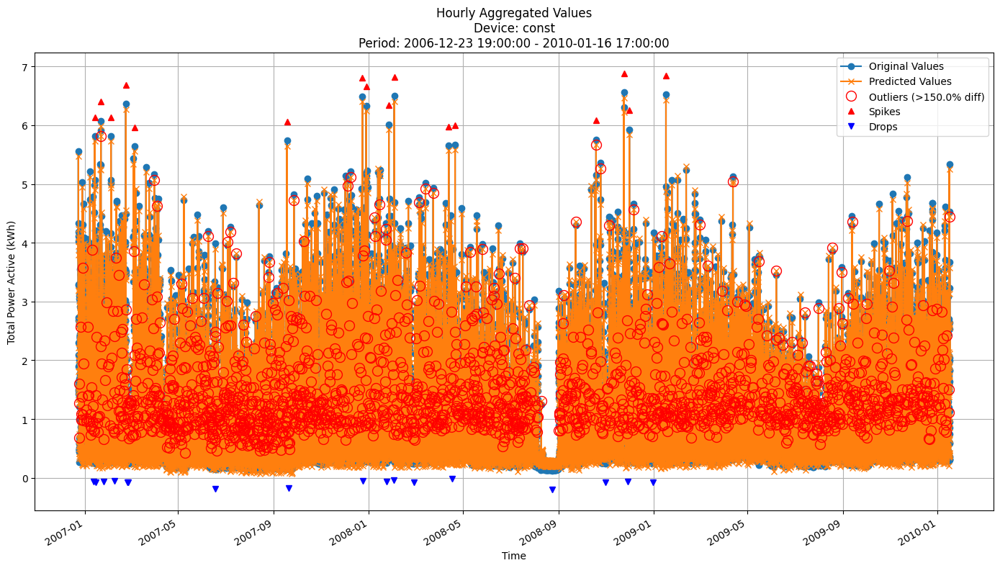


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.6824
MAE: 0.4489
MAPE: 51.6900%

Directional Metrics:
Directional Accuracy: 48.3407%
First-Diff Correlation: -0.0534

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.5000
  Recall: 1.0000
  F1 Score: 0.6667
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [48]:
for device_id in incb_all_train_preds.keys():
    y_train = incb_all_train_preds[device_id][-1]['y_true']
    y_pred_train = incb_all_train_preds[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

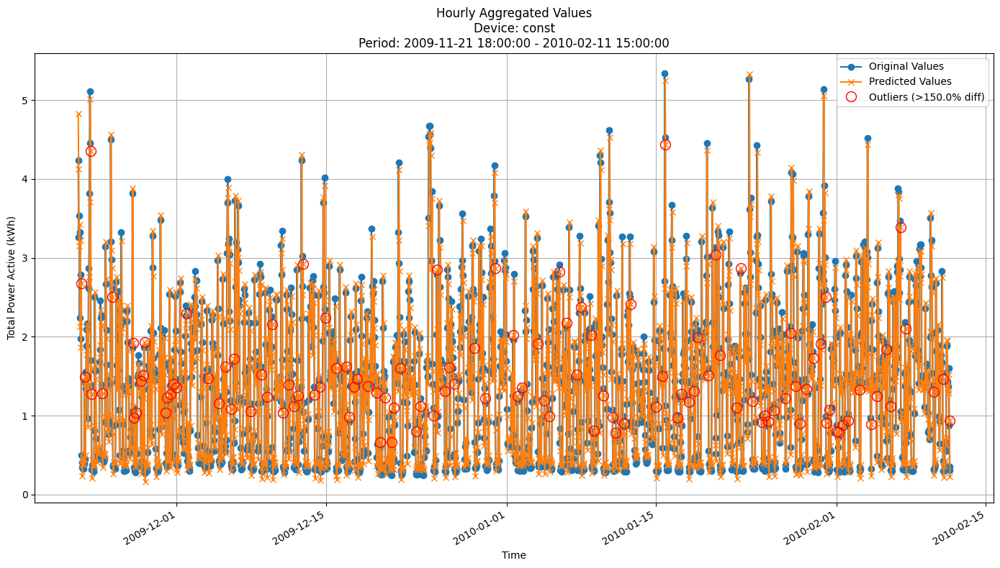


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.7127
MAE: 0.4897
MAPE: 43.7859%

Directional Metrics:
Directional Accuracy: 51.5013%
First-Diff Correlation: -0.0517

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [49]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in incb_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, incb_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, incb_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

## iNcubation Boost (elastic pruning)

In [50]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario:

elastic = IncubationBoostElastic
elastic_params = {
    'length': 50, 
    'learning_rate': 0.001,
    'depth': 5,
    'grace_period': 48,
    'grace_period_depth': -1,
    'split_confidence': 0.1,
    'max_feature': 0.5,
    'tie_threshold': 0.05,
    'bin_type': 'adaptive',
    'max_bins': 32,
    'split_criterion': 'vr_rel',
    'verbose': False,
    'pruning_strategy': 'new_egbdt',
    'wr_fixed_multiplier': 2.0,
    'wr_alpha': 0,
    'wr_beta': 0,
    'wr_gamma': 0,
    'wr_baseline': 0.0,
    'wr_min_keep': 3,
    'wr_error_agg': 'ema',
    'wr_ema_decay': 0,
    'wr_gate_eps': 0,
    'wr_cooldown': 0
}

In [51]:
elastic_all_train_preds, elastic_all_valid_preds, \
elastic_all_train_metrics, elastic_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=elastic, 
    model_params=elastic_params,
    train=train, 
    valid=valid, 
    use_residuals=USE_RESIDUAL,
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    # end_split=1,  # Use only the third and fourth splits
    verbose=1)

Processing splits:   0%|          | 0/40 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 15
Filtered feature count: 15
Excluded lag features: None
Initial training on data from 2006-12-23 19:00:00+01:00 to 2007-01-20 17:00:00+01:00
Model's memory usage: 0.238373 MB
Metrics for Device: const | Period: 2007-01-20 18:00:00+01:00 - 2007-02-17 17:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.8195
	MAE: 0.5698
	MAPE: 47.9567%

Directional Metrics:
	Directional Accuracy: 51.1177%
	First-Diff Correlation: -0.0108

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.7500
		Recall: 1.0000
		F1: 0.8571
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------


Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 15
Filtered feature count: 15
Excluded lag features: None
Initial training on data from 2006-12-23 19:00:00+01:00 to 2007-02-17 17:00:00+01:00
Model's memory usage: 0.398880 MB
Metrics for Device: const | Period: 2007-02-17 18:00:00+01:00 - 2007-03-17 17:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.7270
	MAE: 0.4553
	MAPE: 47.6695%

Directional Metrics:
	Directional Accuracy: 45.6036%
	First-Diff Correlation: -0.0122

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 0.9500
		F1: 0.9744
	Drops:
		Precision: 0.6111
		Recall: 0.5238
		F1: 0.5641
--------------------------------------------------


Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (71 outputs left out)

Processing devices in split 38:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 15
Filtered feature count: 15
Excluded lag features: None
Initial training on data from 2006-12-23 19:00:00+01:00 to 2009-12-19 17:00:00+01:00
Model's memory usage: 0.898369 MB
Metrics for Device: const | Period: 2009-12-19 18:00:00+01:00 - 2010-01-16 17:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.6879
	MAE: 0.4631
	MAPE: 41.7146%

Directional Metrics:
	Directional Accuracy: 53.3532%
	First-Diff Correlation: -0.0253

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 0.2000
		Recall: 0.2000
		F1: 0.2000
--------------------------------------------------


Processing devices in split 39:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 15
Filtered feature count: 15
Excluded lag features: None
Initial training on data from 2006-12-23 19:00:00+01:00 to 2010-01-16 17:00:00+01:00
Model's memory usage: 0.629669 MB
Metrics for Device: const | Period: 2010-01-16 18:00:00+01:00 - 2010-02-11 15:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.7247
	MAE: 0.5080
	MAPE: 44.0325%

Directional Metrics:
	Directional Accuracy: 50.8857%
	First-Diff Correlation: -0.0625

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.8889
		Recall: 0.8889
		F1: 0.8889
	Drops:
		Precision: 0.1250
		Recall: 0.1250
		F1: 0.1250
--------------------------------------------------


### Results

In [52]:
print("\n\nTrain period metrics:")
elastic_all_time_train_metrics = all_time_aggregation_metrics(elastic_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
elastic_all_time_valid_metrics = all_time_aggregation_metrics(elastic_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: const
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.7060 ± 0.0294
	MAE: 0.4650 ± 0.0258
	MAPE: 52.4130% ± 4.7018%

	Directional Metrics:
		Directional Accuracy: 48.5958% ± 0.6745%
		First-Diff Correlation: -0.0430 ± 0.0112

	Immediate Detection (delta=0):
		Spike Precision: 0.0233 ± 0.0174
		Spike Recall: 0.0266 ± 0.0201
		Spike F1: 0.0248 ± 0.0186
		Drop Precision: 0.0289 ± 0.0186
		Drop Recall: 0.0330 ± 0.0226
		Drop F1: 0.0308 ± 0.0203

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.8328 ± 0.0815
		Spike Recall: 0.9607 ± 0.0398
		Spike F1: 0.8906 ± 0.0587
		Drop Precision: 0.5045 ± 0.1735
		Drop Recall: 0.5716 ± 0.1934
		Drop F1: 0.5354 ± 0.1819
Daily Metrics:
	RMSE: 1.5865 ± 0.2933
	MAE: 1.2384 ± 0.2729
	MAPE: 5.3963% ± 1.8784%

	Directional Metrics:
		Directional Accuracy: 93.8582% ± 0.7298%
		First-Diff Correlation: 0.9808 ± 0.0036

	Immediate Detection (delta=0):
		Spi

# Test-set Model Evaluation
(`train[-1]` + `valid[-1]`) vs `test`

In [53]:
# Define model classes and params for test-set evaluation
models_classes = [bl_prev, bl_mean, gbdt, rf, hoef, arf_hf, fodt, arf, incb, elastic]
models_params = [
    bl_prev_params,
    bl_mean_params,
    gbdt_params,
    rf_params,
    hoef_params,
    arf_hf_params,
    fodt_params,
    arf_params,
    incb_params,
    elastic_params
]

model_test_results = {}
for model_class, params in zip(models_classes, models_params):
    if model_class in [gbdt, rf, bl_mean]:
        incremental = False
        update_freq = "14D"
        print(f"Model: {model_class.__name__} - update_freq: {update_freq}")
    else:
        incremental = True
        update_freq = "1h"
        print(f"Model: {model_class.__name__} - update_freq: {update_freq}")

    _, test_preds, \
    _, test_metrics = test_set_seq_fit_predict(
        model_class=model_class,
        model_params=params,
        train=train,
        valid=valid,
        test=test,
        use_residuals=USE_RESIDUAL,
        incremental=incremental,
        data_freq=DATA_FREQUENCY,
        forecast_horizon=FORECAST_HORIZON,
        features=ALL_FEATURES,
        update_freq=update_freq,
        spike_prominence=SPIKE_PROMINENCE,
        normalize_robust=True,
        predict_train=False,
        verbose=True
    )
    model_test_results[model_class.__name__] = {
        "test_preds": test_preds,
        "test_metrics": test_metrics
    }

Model: PreviousValueRegressor - update_freq: 1h


Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 15
Filtered feature count: 15
Excluded lag features: None
Initial training on data from 2006-12-23 19:00:00+01:00 to 2010-02-11 15:00:00+01:00
Model's memory usage: 0.000313 MB
Metrics for Device: const | Period: 2010-02-11 17:00:00+01:00 - 2010-11-26 21:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.5922
	MAE: 0.3875
	MAPE: 44.6214%

Directional Metrics:
	Directional Accuracy: 48.2504%
	First-Diff Correlation: -0.0995

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.9921
		Recall: 1.0000
		F1: 0.9960
	Drops:
		Precision: 0.9921
		Recall: 1.0000
		F1: 0.9960
--------------------------------------------------


Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2006-12-23 19:00:00+01:00 to 2010-02-11 15:00:00+01:00

Time: 0.01 seconds
Predicting for chunk from 2010-02-11 17:00:00+01:00 to 2010-02-25 17:00:00+01:00

-------------------------

Retraining model on data from 2006-12-23 19:00:00+01:00 to 2010-02-25 17:00:00+01:00

Time: 0.01 seconds
Predicting for chunk from 2010-02-25 18:00:00+01:00 to 2010-03-11 18:00:00+01:00

-------------------------

Retraining model on data from 2006-12-23 19:00:00+01:00 to 2010-03-11 18:00:00+01:00

Time: 0.02 seconds
Predicting for chunk from 2010-03-11 19:00:00+01:00 to 2010-03-25 19:00:00+01:00

-------------------------

Retraining model on data from 2006-12-23 19:00:00+01:00 to 2010-03-25 19:00:00+01:00

Time: 0.01 seconds
Predicting for chunk from 2010-03-25 20:00:00+01:00 to 2010-04-08 21:00:00+02:00

-------------------------

Retraining model on data from 2006-12-23 19:00:00+01:00 to 2010-04-08 21:00:00+02:00

Time: 0.02 seconds
Predicting for chunk from 2010-04-08 2

Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]

... (11 outputs left out)

Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 15
Filtered feature count: 15
Excluded lag features: None
Initial training on data from 2006-12-23 19:00:00+01:00 to 2010-02-11 15:00:00+01:00
Model's memory usage: 0.121819 MB
Metrics for Device: const | Period: 2010-02-11 17:00:00+01:00 - 2010-11-26 21:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.5826
	MAE: 0.3866
	MAPE: 45.7356%

Directional Metrics:
	Directional Accuracy: 49.2047%
	First-Diff Correlation: -0.0889

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0119
		Recall: 0.0159
		F1: 0.0136
	Drops:
		Precision: 0.0539
		Recall: 0.0714
		F1: 0.0614

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.7381
		Recall: 0.9841
		F1: 0.8435
	Drops:
		Precision: 0.3772
		Recall: 0.5000
		F1: 0.4300
--------------------------------------------------


Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 15
Filtered feature count: 15
Excluded lag features: None
Initial training on data from 2006-12-23 19:00:00+01:00 to 2010-02-11 15:00:00+01:00
Model's memory usage: 0.768959 MB
Metrics for Device: const | Period: 2010-02-11 17:00:00+01:00 - 2010-11-26 21:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.5798
	MAE: 0.3858
	MAPE: 45.5910%

Directional Metrics:
	Directional Accuracy: 50.0723%
	First-Diff Correlation: -0.0870

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0163
		Recall: 0.0238
		F1: 0.0194
	Drops:
		Precision: 0.0761
		Recall: 0.1111
		F1: 0.0903

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.6739
		Recall: 0.9841
		F1: 0.8000
	Drops:
		Precision: 0.3043
		Recall: 0.4444
		F1: 0.3613
--------------------------------------------------


In [54]:
for model_class in models_classes:
    model_test_results[model_class.__name__]['test_metrics'] = all_time_aggregation_metrics(
        model_test_results[model_class.__name__]['test_metrics'],
        data_freq=DATA_FREQUENCY,
        verbose=False)

# Model Comparison

In [55]:
AGG_LEVEL = "hourly"
METRICS = ["rmse", "mae", "mape", "dir_accuracy", "first_diff_corr"]
PERC_METRICS = ["mape", "dir_accuracy", "first_diff_corr"]
# SPIKES_METRICS = ["spikes_immediate.precision", "spikes_immediate.recall", "spikes_immediate.f1",
#                   "spikes_delayed.precision", "spikes_delayed.recall", "spikes_delayed.f1",
#                   "drops_immediate.precision", "drops_immediate.recall", "drops_immediate.f1",
#                   "drops_delayed.precision", "drops_delayed.recall", "drops_delayed.f1"]
SPIKES_METRICS = ["spikes_immediate.f1", "spikes_delayed.f1",
                  "drops_immediate.f1", "drops_delayed.f1"]

METRICS.extend(SPIKES_METRICS)
PERC_METRICS.extend(SPIKES_METRICS)

## Test results

In [56]:
MODEL_TEST_METRICS = {
    "BL_Prev": model_test_results[bl_prev.__name__]["test_metrics"],
    "BL_Mean": model_test_results[bl_mean.__name__]["test_metrics"],
    "GBDT": model_test_results[gbdt.__name__]["test_metrics"],
    "RandomForest": model_test_results[rf.__name__]["test_metrics"],
    "HoeffdingTree": model_test_results[hoef.__name__]["test_metrics"],
    "ARF_Hoeffding": model_test_results[arf_hf.__name__]["test_metrics"],
    "FastODT": model_test_results[fodt.__name__]["test_metrics"],
    "ARF_FastODT": model_test_results[arf.__name__]["test_metrics"],
    "IncubationBoost": model_test_results[incb.__name__]["test_metrics"],
    "IncubationBoostElastic": model_test_results[elastic.__name__]["test_metrics"],
}

In [57]:
def format_metric(val, is_perc=False):
    if isinstance(val, dict) and "mean" in val and "std" in val:
        mean = val["mean"]
        std = val["std"]
        if is_perc:
            mean = mean * 100
            std = std * 100
        return f"{mean:.3f} ± {std:.3f}"
    if is_perc:
        return f"{val*100:.3f}" if val is not None else None
    return f"{val:.3f}" if val is not None else None

def display_aggregated_results(model_metrics, device_ids, agg_level):
    for device_id in device_ids:
        rows = []
        for model, mdict in model_metrics.items():
            if device_id in mdict and agg_level in mdict[device_id]:
                vals = mdict[device_id][agg_level]
                row = [model]
                for m in METRICS:
                    is_perc = (m in PERC_METRICS)
                    row.append(format_metric(vals.get(m, None), is_perc=is_perc))
                rows.append(row)
        df = pd.DataFrame(rows, columns=["Model", "RMSE", "MAE", "MAPE (%)", "Directional Accuracy (%)", "First Diff Corr (%)",
                                         "Spikes Immediate F1 (%)", "Spikes Delayed F1 (%)", "Drops Immediate F1 (%)", "Drops Delayed F1 (%)"])
        print(f"\n\nDevice: {device_id} | Aggregation: {agg_level}")
        display(df)

In [58]:
device_ids = set()
for m in MODEL_TEST_METRICS.values():
    device_ids.update(m.keys())
device_ids = sorted(device_ids)

print("\n\n============================Hourly Test Results============================")
display_aggregated_results(MODEL_TEST_METRICS, device_ids, AGG_LEVEL)



============================Hourly Test Results============================


Device: const | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,0.592 ± 0.000,0.388 ± 0.000,44.621 ± 0.000,48.250 ± 0.000,-9.946 ± 0.000,0.000 ± 0.000,99.605 ± 0.000,0.000 ± 0.000,99.605 ± 0.000
1,BL_Mean,0.554 ± 0.000,0.378 ± 0.000,48.709 ± 0.000,52.053 ± 0.000,-2.235 ± 0.000,2.667 ± 0.000,71.111 ± 0.000,8.000 ± 0.000,22.222 ± 0.000
2,GBDT,0.572 ± 0.000,0.375 ± 0.000,43.726 ± 0.000,49.639 ± 0.000,-8.515 ± 0.000,1.481 ± 0.000,90.370 ± 0.000,5.185 ± 0.000,57.037 ± 0.000
3,RandomForest,0.527 ± 0.000,0.359 ± 0.000,46.124 ± 0.000,51.634 ± 0.000,0.630 ± 0.000,5.818 ± 0.000,77.091 ± 0.000,8.696 ± 0.000,28.261 ± 0.000
4,HoeffdingTree,0.591 ± 0.000,0.388 ± 0.000,45.314 ± 0.000,48.424 ± 0.000,-9.867 ± 0.000,2.335 ± 0.000,95.720 ± 0.000,0.778 ± 0.000,79.377 ± 0.000
5,ARF_Hoeffding,0.565 ± 0.000,0.379 ± 0.000,46.671 ± 0.000,50.072 ± 0.000,-7.479 ± 0.000,4.167 ± 0.000,83.333 ± 0.000,6.944 ± 0.000,36.111 ± 0.000
6,FastODT,0.592 ± 0.000,0.388 ± 0.000,44.619 ± 0.000,48.250 ± 0.000,-9.946 ± 0.000,0.000 ± 0.000,99.605 ± 0.000,0.000 ± 0.000,99.605 ± 0.000
7,ARF_FastODT,0.572 ± 0.000,0.394 ± 0.000,49.727 ± 0.000,48.554 ± 0.000,-7.479 ± 0.000,2.007 ± 0.000,78.261 ± 0.000,2.007 ± 0.000,54.181 ± 0.000
8,IncubationBoost,0.583 ± 0.000,0.387 ± 0.000,45.736 ± 0.000,49.205 ± 0.000,-8.892 ± 0.000,1.361 ± 0.000,84.354 ± 0.000,6.143 ± 0.000,43.003 ± 0.000
9,IncubationBoostElastic,0.580 ± 0.000,0.386 ± 0.000,45.591 ± 0.000,50.072 ± 0.000,-8.697 ± 0.000,1.935 ± 0.000,80.000 ± 0.000,9.032 ± 0.000,36.129 ± 0.000


<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>Model</th>
      <th>RMSE</th>
      <th>MAE</th>
      <th>MAPE (%)</th>
      <th>Directional Accuracy (%)</th>
      <th>First Diff Corr (%)</th>
      <th>Spikes Immediate F1 (%)</th>
      <th>Spikes Delayed F1 (%)</th>
      <th>Drops Immediate F1 (%)</th>
      <th>Drops Delayed F1 (%)</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>0</th>
      <td>BL_Prev</td>
      <td>0.592 ± 0.000</td>
      <td>0.388 ± 0.000</td>
      <td>44.621 ± 0.000</td>
      <td>48.250 ± 0.000</td>
      <td>-9.946 ± 0.000</td>
      <td>0.000 ± 0.000</td>
      <td>99.605 ± 0.000</td>
      <td>0.000 ± 0.000</td>
      <td>99.605 ± 0.000</td>
    </tr>
    <tr>
      <th>1</th>
      <td>BL_Mean</td>
      <td>0.554 ± 0.000</td>
      <td>0.378 ± 0.000</td>
      <td>48.709 ± 0.000</td>
      <td>52.053 ± 0.000</td>
      <td>-2.235 ± 0.000</td>
      <td>2.667 ± 0.000</td>
      <td>71.111 ± 0.000</td>
      <td>8.000 ± 0.000</td>
      <td>22.222 ± 0.000</td>
    </tr>
    <tr>
      <th>2</th>
      <td>GBDT</td>
      <td>0.572 ± 0.000</td>
      <td>0.375 ± 0.000</td>
      <td>43.726 ± 0.000</td>
      <td>49.639 ± 0.000</td>
      <td>-8.515 ± 0.000</td>
      <td>1.481 ± 0.000</td>
      <td>90.370 ± 0.000</td>
      <td>5.185 ± 0.000</td>
      <td>57.037 ± 0.000</td>
    </tr>
    <tr>
      <th>3</th>
      <td>RandomForest</td>
      <td>0.527 ± 0.000</td>
      <td>0.359 ± 0.000</td>
      <td>46.124 ± 0.000</td>
      <td>51.634 ± 0.000</td>
      <td>0.630 ± 0.000</td>
      <td>5.818 ± 0.000</td>
      <td>77.091 ± 0.000</td>
      <td>8.696 ± 0.000</td>
      <td>28.261 ± 0.000</td>
    </tr>
    <tr>
      <th>4</th>
      <td>HoeffdingTree</td>
      <td>0.591 ± 0.000</td>
      <td>0.388 ± 0.000</td>
      <td>45.314 ± 0.000</td>
      <td>48.424 ± 0.000</td>
      <td>-9.867 ± 0.000</td>
      <td>2.335 ± 0.000</td>
      <td>95.720 ± 0.000</td>
      <td>0.778 ± 0.000</td>
      <td>79.377 ± 0.000</td>
    </tr>
    <tr>
      <th>5</th>
      <td>ARF_Hoeffding</td>
      <td>0.565 ± 0.000</td>
      <td>0.379 ± 0.000</td>
      <td>46.671 ± 0.000</td>
      <td>50.072 ± 0.000</td>
      <td>-7.479 ± 0.000</td>
      <td>4.167 ± 0.000</td>
      <td>83.333 ± 0.000</td>
      <td>6.944 ± 0.000</td>
      <td>36.111 ± 0.000</td>
    </tr>
    <tr>
      <th>6</th>
      <td>FastODT</td>
      <td>0.592 ± 0.000</td>
      <td>0.388 ± 0.000</td>
      <td>44.619 ± 0.000</td>
      <td>48.250 ± 0.000</td>
      <td>-9.946 ± 0.000</td>
      <td>0.000 ± 0.000</td>
      <td>99.605 ± 0.000</td>
      <td>0.000 ± 0.000</td>
      <td>99.605 ± 0.000</td>
    </tr>
    <tr>
      <th>7</th>
      <td>ARF_FastODT</td>
      <td>0.572 ± 0.000</td>
      <td>0.394 ± 0.000</td>
      <td>49.727 ± 0.000</td>
      <td>48.554 ± 0.000</td>
      <td>-7.479 ± 0.000</td>
      <td>2.007 ± 0.000</td>
      <td>78.261 ± 0.000</td>
      <td>2.007 ± 0.000</td>
      <td>54.181 ± 0.000</td>
    </tr>
    <tr>
      <th>8</th>
      <td>IncubationBoost</td>
      <td>0.583 ± 0.000</td>
      <td>0.385 ± 0.000</td>
      <td>45.106 ± 0.000</td>
      <td>48.048 ± 0.000</td>
      <td>-9.153 ± 0.000</td>
      <td>2.135 ± 0.000</td>
      <td>86.121 ± 0.000</td>
      <td>2.837 ± 0.000</td>
      <td>44.681 ± 0.000</td>
    </tr>
  </tbody>
</table>
</div>

## Validation results

In [59]:
MODEL_VALID_METRICS = {
    "BL_Prev": bl_prev_all_time_valid_metrics,
    "BL_Mean": bl_mean_all_time_valid_metrics,
    "GBDT": gbdt_all_time_valid_metrics,
    "RandomForest": rf_all_time_valid_metrics,
    "HoeffdingTree": hoef_all_time_valid_metrics,
    "ARF_Hoeffding": arf_hf_all_time_valid_metrics,
    "FastODT": fodt_all_time_valid_metrics,
    "ARF_FastODT": arf_all_time_valid_metrics,
    "IncubationBoost": incb_all_time_valid_metrics,
    "IncubationBoostElastic": elastic_all_time_valid_metrics,
}


device_ids = set()
for m in MODEL_VALID_METRICS.values():
    device_ids.update(m.keys())
device_ids = sorted(device_ids)


print("\n\n============================Hourly Validation Results============================")
display_aggregated_results(MODEL_VALID_METRICS, device_ids, AGG_LEVEL)



============================Hourly Validation Results============================


Device: const | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,0.681 ± 0.125,0.447 ± 0.095,48.828 ± 6.995,47.703 ± 5.045,-7.028 ± 6.781,0.000 ± 0.000,98.897 ± 2.466,0.000 ± 0.000,98.963 ± 2.626
1,BL_Mean,0.636 ± 0.091,0.434 ± 0.063,55.547 ± 15.360,52.802 ± 3.263,0.534 ± 8.307,4.021 ± 5.756,67.826 ± 17.620,3.851 ± 5.539,16.897 ± 11.358
2,GBDT,0.659 ± 0.120,0.432 ± 0.089,48.036 ± 6.656,49.252 ± 4.927,-5.642 ± 6.896,1.365 ± 2.532,92.106 ± 8.967,2.822 ± 4.972,51.993 ± 21.797
3,RandomForest,0.593 ± 0.019,0.401 ± 0.010,49.146 ± 4.248,53.653 ± 1.957,11.087 ± 6.310,12.411 ± 9.135,80.385 ± 5.549,6.512 ± 2.598,24.966 ± 8.238
4,HoeffdingTree,0.676 ± 0.123,0.448 ± 0.093,50.369 ± 7.418,47.816 ± 4.716,-6.422 ± 6.818,3.269 ± 8.851,90.592 ± 11.444,0.960 ± 2.214,63.759 ± 23.329
5,ARF_Hoeffding,0.649 ± 0.111,0.438 ± 0.082,52.926 ± 7.770,50.035 ± 4.674,-4.966 ± 7.256,3.969 ± 4.641,81.684 ± 11.207,5.583 ± 6.695,32.714 ± 20.043
6,FastODT,0.681 ± 0.125,0.447 ± 0.095,48.815 ± 6.989,47.691 ± 5.034,-7.028 ± 6.782,0.000 ± 0.000,98.897 ± 2.466,0.000 ± 0.000,98.899 ± 2.689
7,ARF_FastODT,0.680 ± 0.125,0.448 ± 0.095,49.062 ± 6.841,47.694 ± 5.040,-6.947 ± 6.806,0.000 ± 0.000,98.392 ± 3.178,0.000 ± 0.000,95.977 ± 13.095
8,IncubationBoost,0.680 ± 0.125,0.447 ± 0.094,48.857 ± 6.947,47.831 ± 5.066,-6.983 ± 6.827,0.327 ± 1.843,97.215 ± 6.381,0.202 ± 0.931,87.799 ± 27.036
9,IncubationBoostElastic,0.667 ± 0.117,0.446 ± 0.085,51.950 ± 9.035,48.239 ± 4.704,-5.622 ± 6.740,2.253 ± 3.882,87.768 ± 8.964,3.679 ± 6.004,48.476 ± 25.807


<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>Model</th>
      <th>RMSE</th>
      <th>MAE</th>
      <th>MAPE (%)</th>
      <th>Directional Accuracy (%)</th>
      <th>First Diff Corr (%)</th>
      <th>Spikes Immediate F1 (%)</th>
      <th>Spikes Delayed F1 (%)</th>
      <th>Drops Immediate F1 (%)</th>
      <th>Drops Delayed F1 (%)</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>0</th>
      <td>BL_Prev</td>
      <td>0.681 ± 0.125</td>
      <td>0.447 ± 0.095</td>
      <td>48.828 ± 6.995</td>
      <td>47.703 ± 5.045</td>
      <td>-7.028 ± 6.781</td>
      <td>0.000 ± 0.000</td>
      <td>98.897 ± 2.466</td>
      <td>0.000 ± 0.000</td>
      <td>98.963 ± 2.626</td>
    </tr>
    <tr>
      <th>1</th>
      <td>BL_Mean</td>
      <td>0.636 ± 0.091</td>
      <td>0.434 ± 0.063</td>
      <td>55.547 ± 15.360</td>
      <td>52.802 ± 3.263</td>
      <td>0.534 ± 8.307</td>
      <td>4.021 ± 5.756</td>
      <td>67.826 ± 17.620</td>
      <td>3.851 ± 5.539</td>
      <td>16.897 ± 11.358</td>
    </tr>
    <tr>
      <th>2</th>
      <td>GBDT</td>
      <td>0.659 ± 0.120</td>
      <td>0.432 ± 0.089</td>
      <td>48.036 ± 6.656</td>
      <td>49.252 ± 4.927</td>
      <td>-5.642 ± 6.896</td>
      <td>1.365 ± 2.532</td>
      <td>92.106 ± 8.967</td>
      <td>2.822 ± 4.972</td>
      <td>51.993 ± 21.797</td>
    </tr>
    <tr>
      <th>3</th>
      <td>RandomForest</td>
      <td>0.593 ± 0.019</td>
      <td>0.401 ± 0.010</td>
      <td>49.146 ± 4.248</td>
      <td>53.653 ± 1.957</td>
      <td>11.087 ± 6.310</td>
      <td>12.411 ± 9.135</td>
      <td>80.385 ± 5.549</td>
      <td>6.512 ± 2.598</td>
      <td>24.966 ± 8.238</td>
    </tr>
    <tr>
      <th>4</th>
      <td>HoeffdingTree</td>
      <td>0.676 ± 0.123</td>
      <td>0.448 ± 0.093</td>
      <td>50.369 ± 7.418</td>
      <td>47.816 ± 4.716</td>
      <td>-6.422 ± 6.818</td>
      <td>3.269 ± 8.851</td>
      <td>90.592 ± 11.444</td>
      <td>0.960 ± 2.214</td>
      <td>63.759 ± 23.329</td>
    </tr>
    <tr>
      <th>5</th>
      <td>ARF_Hoeffding</td>
      <td>0.649 ± 0.111</td>
      <td>0.438 ± 0.082</td>
      <td>52.926 ± 7.770</td>
      <td>50.035 ± 4.674</td>
      <td>-4.966 ± 7.256</td>
      <td>3.969 ± 4.641</td>
      <td>81.684 ± 11.207</td>
      <td>5.583 ± 6.695</td>
      <td>32.714 ± 20.043</td>
    </tr>
    <tr>
      <th>6</th>
      <td>FastODT</td>
      <td>0.681 ± 0.125</td>
      <td>0.447 ± 0.095</td>
      <td>48.815 ± 6.989</td>
      <td>47.691 ± 5.034</td>
      <td>-7.028 ± 6.782</td>
      <td>0.000 ± 0.000</td>
      <td>98.897 ± 2.466</td>
      <td>0.000 ± 0.000</td>
      <td>98.899 ± 2.689</td>
    </tr>
    <tr>
      <th>7</th>
      <td>ARF_FastODT</td>
      <td>0.680 ± 0.125</td>
      <td>0.448 ± 0.095</td>
      <td>49.062 ± 6.841</td>
      <td>47.694 ± 5.040</td>
      <td>-6.947 ± 6.806</td>
      <td>0.000 ± 0.000</td>
      <td>98.392 ± 3.178</td>
      <td>0.000 ± 0.000</td>
      <td>95.977 ± 13.095</td>
    </tr>
    <tr>
      <th>8</th>
      <td>IncubationBoost</td>
      <td>0.670 ± 0.121</td>
      <td>0.443 ± 0.090</td>
      <td>49.318 ± 6.227</td>
      <td>47.768 ± 4.754</td>
      <td>-6.369 ± 7.042</td>
      <td>0.670 ± 2.007</td>
      <td>89.593 ± 12.268</td>
      <td>2.099 ± 6.103</td>
      <td>56.048 ± 31.197</td>
    </tr>
  </tbody>
</table>
</div>

### By-period validation results

In [60]:
MODEL_VALID_PERIOD_METRICS = {
    "BL_Mean": bl_prev_valid_period_metrics,
    "BL_Prev": bl_mean_valid_period_metrics,
    "GBDT": gbdt_valid_period_metrics,
    "RandomForest": rf_valid_period_metrics,
    "HoeffdingTree": hoef_all_valid_metrics,
    "ARF_Hoeffding": arf_hf_all_valid_metrics,
    "FastODT": fodt_all_valid_metrics,
    "ARF_FastODT": arf_all_valid_metrics,
    "IncubationBoost": incb_all_valid_metrics,
}

def show_per_period_metric_tables(device_ids, MODEL_VALID_PERIOD_METRICS, AGG_LEVEL, metric_name, display_gain=True):
    """
    Display per-period metric tables and gain/drop tables for a given metric.
    Args:
        device_ids: List of device IDs to display metrics for.
        MODEL_VALID_PERIOD_METRICS: Dictionary containing model period metrics.
        AGG_LEVEL: Aggregation level (e.g., "hourly").
        metric_name: The name of the metric to display.
        display_gain: Whether to display gain/drop tables.
    """
    for device_id in device_ids:
        period_vals = {}
        n_periods = None
        for model, mdict in MODEL_VALID_PERIOD_METRICS.items():
                if metric_name in PERC_METRICS:
                    vals = [period[AGG_LEVEL][metric_name]*100 for period in mdict[device_id]]
                    period_vals[model] = [f"{v:.3f}" for v in vals]
                else:
                    vals = [period[AGG_LEVEL][metric_name] for period in mdict[device_id]]
                    period_vals[model] = [f"{v:.3f}" for v in vals]
                n_periods = len(vals)
        if not period_vals:
            continue

        df_metric = pd.DataFrame(period_vals)
        df_metric.index = [f"Period {i+1}" for i in range(n_periods)]
        df_metric['Agg. Per Period'] = df_metric.astype(float).mean(axis=1)

        metric_label = f"{metric_name.upper()} (%)" if metric_name in PERC_METRICS else metric_name.upper()
        print(f"\nDevice: {device_id} | Aggregation: {AGG_LEVEL} | {metric_label} per period")
        display(df_metric)


        if display_gain:
            # Absolute gain/drop
            abs_gain = df_metric.astype(float).diff().iloc[1:]
            abs_gain = abs_gain.applymap(lambda v: f"{v:.3f}")
            abs_gain.index = [f"{df_metric.index[i]} - {df_metric.index[i-1]}" for i in range(1, len(df_metric))]
            print(f"\nAbsolute gain/drop in {metric_label}:")
            display(abs_gain)
            # Percentage gain/drop
            # pct_gain = df_metric.astype(float).pct_change().iloc[1:] * 100
            # pct_gain = pct_gain.applymap(lambda v: f"{v:.3f}")
            # pct_gain.index = abs_gain.index
            # print(f"\nPercentage gain/drop in {metric_label} (lower is better):")
            # display(pct_gain)

#### Directional accuracy (higher is better)


In [61]:
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="dir_accuracy",
    display_gain=True
)


Device: const | Aggregation: hourly | DIR_ACCURACY (%) per period


,BL_Mean,BL_Prev,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,50.373,55.440,50.969,55.440,50.969,55.738,50.373,50.373,50.373,52.227556
Period 2,44.262,51.416,46.647,51.416,44.113,50.671,44.262,44.262,44.262,46.812333
Period 3,49.478,56.036,51.118,52.608,50.820,52.161,49.478,49.478,49.478,51.183889
Period 4,48.733,53.502,49.776,53.949,48.733,49.776,48.733,48.733,48.733,50.074222
Period 5,43.368,53.353,46.051,52.161,43.070,48.435,43.368,43.368,43.368,46.282444
Period 6,52.906,52.757,52.906,51.565,51.863,51.863,52.906,52.906,52.906,52.508667
Period 7,44.560,46.498,45.753,48.286,45.306,47.690,44.560,44.560,44.560,45.752556
Period 8,45.753,50.522,47.988,50.969,46.796,52.161,45.753,45.753,45.753,47.938667
Period 9,50.075,54.396,52.608,53.353,50.522,50.671,50.075,50.075,50.075,51.316667
Period 10,53.502,57.228,55.738,55.738,52.608,53.353,53.502,53.502,53.502,54.297000



Absolute gain/drop in DIR_ACCURACY (%):


,BL_Mean,BL_Prev,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,-6.111,-4.024,-4.322,-4.024,-6.856,-5.067,-6.111,-6.111,-6.111,-5.415
Period 3 - Period 2,5.216,4.620,4.471,1.192,6.707,1.490,5.216,5.216,5.216,4.372
Period 4 - Period 3,-0.745,-2.534,-1.342,1.341,-2.087,-2.385,-0.745,-0.745,-0.745,-1.110
Period 5 - Period 4,-5.365,-0.149,-3.725,-1.788,-5.663,-1.341,-5.365,-5.365,-5.365,-3.792
Period 6 - Period 5,9.538,-0.596,6.855,-0.596,8.793,3.428,9.538,9.538,9.538,6.226
Period 7 - Period 6,-8.346,-6.259,-7.153,-3.279,-6.557,-4.173,-8.346,-8.346,-8.346,-6.756
Period 8 - Period 7,1.193,4.024,2.235,2.683,1.490,4.471,1.193,1.193,1.193,2.186
Period 9 - Period 8,4.322,3.874,4.620,2.384,3.726,-1.490,4.322,4.322,4.322,3.378
Period 10 - Period 9,3.427,2.832,3.130,2.385,2.086,2.682,3.427,3.427,3.427,2.980
Period 11 - Period 10,-3.129,-1.043,-2.981,-2.087,-2.086,2.832,-3.129,-3.129,-3.129,-1.987


#### MAPE (lower is better)

In [62]:
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="mape",
    display_gain=True
)


Device: const | Aggregation: hourly | MAPE (%) per period


,BL_Mean,BL_Prev,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,45.796,50.916,45.156,46.226,49.160,48.794,45.741,45.749,45.802,47.037778
Period 2,45.105,71.756,48.923,76.063,50.572,60.733,45.060,45.062,45.104,54.264222
Period 3,47.977,60.398,48.231,53.140,51.737,52.875,47.946,47.945,47.980,50.914333
Period 4,60.805,70.474,59.747,62.240,64.855,64.635,60.761,60.756,60.803,62.786222
Period 5,52.756,55.095,51.225,53.099,53.614,53.471,52.733,52.728,52.758,53.053222
Period 6,60.980,73.645,61.174,69.916,65.489,71.546,60.929,60.919,60.975,65.063667
Period 7,64.396,91.116,65.640,80.009,67.443,73.561,64.369,64.362,64.397,70.588111
Period 8,59.190,94.341,61.303,78.543,63.145,71.856,59.152,59.144,59.187,67.317889
Period 9,66.132,69.111,63.192,61.446,68.638,68.156,66.105,66.098,66.132,66.112222
Period 10,51.159,49.034,48.922,47.122,52.208,52.532,51.140,51.138,51.160,50.490556



Absolute gain/drop in MAPE (%):


,BL_Mean,BL_Prev,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,-0.691,20.840,3.767,29.837,1.412,11.939,-0.681,-0.687,-0.698,7.226
Period 3 - Period 2,2.872,-11.358,-0.692,-22.923,1.165,-7.858,2.886,2.883,2.876,-3.350
Period 4 - Period 3,12.828,10.076,11.516,9.100,13.118,11.760,12.815,12.811,12.823,11.872
Period 5 - Period 4,-8.049,-15.379,-8.522,-9.141,-11.241,-11.164,-8.028,-8.028,-8.045,-9.733
Period 6 - Period 5,8.224,18.550,9.949,16.817,11.875,18.075,8.196,8.191,8.217,12.010
Period 7 - Period 6,3.416,17.471,4.466,10.093,1.954,2.015,3.440,3.443,3.422,5.524
Period 8 - Period 7,-5.206,3.225,-4.337,-1.466,-4.298,-1.705,-5.217,-5.218,-5.210,-3.270
Period 9 - Period 8,6.942,-25.230,1.889,-17.097,5.493,-3.700,6.953,6.954,6.945,-1.206
Period 10 - Period 9,-14.973,-20.077,-14.270,-14.324,-16.430,-15.624,-14.965,-14.960,-14.972,-15.622
Period 11 - Period 10,-5.103,8.545,-3.174,8.887,-4.260,1.890,-5.096,-5.096,-5.103,-0.946


#### RMSE (lower is better)

In [63]:
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="rmse",
    display_gain=True
)


Device: const | Aggregation: hourly | RMSE per period


,BL_Mean,BL_Prev,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,0.826,0.795,0.809,0.771,0.823,0.790,0.827,0.827,0.827,0.810556
Period 2,0.739,0.721,0.721,0.709,0.730,0.713,0.740,0.740,0.740,0.728111
Period 3,0.764,0.725,0.743,0.684,0.753,0.713,0.765,0.765,0.765,0.741889
Period 4,0.640,0.632,0.620,0.575,0.643,0.625,0.640,0.640,0.640,0.628333
Period 5,0.676,0.642,0.657,0.631,0.677,0.652,0.676,0.676,0.676,0.662556
Period 6,0.658,0.639,0.639,0.607,0.654,0.642,0.658,0.658,0.658,0.645889
Period 7,0.575,0.587,0.561,0.538,0.577,0.567,0.575,0.575,0.575,0.570000
Period 8,0.634,0.658,0.619,0.588,0.636,0.608,0.634,0.634,0.634,0.627222
Period 9,0.773,0.704,0.743,0.664,0.774,0.730,0.773,0.773,0.773,0.745222
Period 10,0.772,0.676,0.743,0.662,0.763,0.711,0.772,0.772,0.772,0.738111



Absolute gain/drop in RMSE:


,BL_Mean,BL_Prev,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,-0.087,-0.074,-0.088,-0.062,-0.093,-0.077,-0.087,-0.087,-0.087,-0.082
Period 3 - Period 2,0.025,0.004,0.022,-0.025,0.023,0.000,0.025,0.025,0.025,0.014
Period 4 - Period 3,-0.124,-0.093,-0.123,-0.109,-0.110,-0.088,-0.125,-0.125,-0.125,-0.114
Period 5 - Period 4,0.036,0.010,0.037,0.056,0.034,0.027,0.036,0.036,0.036,0.034
Period 6 - Period 5,-0.018,-0.003,-0.018,-0.024,-0.023,-0.010,-0.018,-0.018,-0.018,-0.017
Period 7 - Period 6,-0.083,-0.052,-0.078,-0.069,-0.077,-0.075,-0.083,-0.083,-0.083,-0.076
Period 8 - Period 7,0.059,0.071,0.058,0.050,0.059,0.041,0.059,0.059,0.059,0.057
Period 9 - Period 8,0.139,0.046,0.124,0.076,0.138,0.122,0.139,0.139,0.139,0.118
Period 10 - Period 9,-0.001,-0.028,0.000,-0.002,-0.011,-0.019,-0.001,-0.001,-0.001,-0.007
Period 11 - Period 10,-0.040,0.009,-0.034,-0.002,-0.045,-0.017,-0.040,-0.040,-0.040,-0.028
